# Respuesta farmacológica multimodal en cáncer
## Resultados finales · evidencia, controles y límites de generalización

**Informe reproducible — 1 de octubre de 2026.** Resultados finales del checkpoint
de los pasos 2–6 del roadmap. Figuras en español, exportadas también en PNG a
300 dpi, SVG y PDF. Este notebook regenera las figuras, **no reentrena modelos**.

**Lectura principal:** Random Forest con dianas y expresión obtiene el menor
RMSE medio del conjunto principal; las anotaciones mezclan información genética
y farmacológica; la armonización de dosis no elimina el cambio de ensayo; los
intervalos no alcanzan su objetivo de cobertura simultánea en PRISM.

### Alcance y navegación
1. Cohortes y armonización de curvas.
2. Rendimiento cold-drug, resultados por fold y predicciones fuera de muestra.
3. Ajuste de Random Forest y bootstrap por fármaco.
4. Controles por permutación, solo grafos y vistas de anotación.
5. Transferencia, concordancia de ensayos y sensibilidad química.
6. Calibración, cobertura y amplitud de intervalos.
7. Inventario completo, validación y procedencia.

Se muestran todos los modelos/variantes del informe final vigente, más B0.
Los resultados históricos de B1–B5 y otros splits pendientes de actualización
**no se mezclan** con estos ajustes corregidos. Cinco folds con entrenamiento
solapado no son cinco estudios independientes. PRISM ya fue examinado: estos
resultados son exploratorios, sin interpretación clínica ni causal.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from IPython.display import display, Image, Markdown

# Funciona al abrir desde la raíz del repositorio o desde notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/reports/roadmap_2_6_summary.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Abra el notebook dentro del repositorio mcdrp.")
REPORTS = ROOT / "data/reports"
OUT = ROOT / "figures/final_results"
OUT.mkdir(parents=True, exist_ok=True)

def load(name):
    return json.loads((REPORTS / name).read_text(encoding="utf-8"))

report = load("roadmap_2_6_summary.json")
snapshot = load("final_results_plot_data.json")
validation = load("roadmap_2_6_validation.json")
harm = load("harmonization_summary.json")
annotation = load("target_annotations_summary.json")
embedding = load("drug_embeddings_pinned_audit.json")
dreval = load("dreval_crosscheck_summary.json")
folds = pd.DataFrame(snapshot["fold_metrics"])
test = folds.loc[folds["subset"].eq("test")].copy()
baseline = test.loc[(test.stage == "B0") & (test.model == "mean_effects")]
assert len(baseline) == 5
assert report["n_folds"] == 5 and len(report["aggregate_test"]) == 23
for row in report["aggregate_test"]:
    actual = test.loc[(test.stage == row["stage"]) & (test.model == row["model"])
                      & (test.variant == row["variant"]), "rmse"].mean()
    assert np.isclose(actual, row["rmse_mean"], atol=1e-8), "Snapshot obsoleto"

# Los archivos grandes son opcionales: los datos compactos versionados bastan
# para todas las figuras. Si están presentes, se comprueba su integridad.
verified = 0
for relative, expected in snapshot["source_sha256"].items():
    path = ROOT / relative
    if path.exists():
        h = hashlib.sha256()
        with path.open("rb") as stream:
            for block in iter(lambda: stream.read(1024 * 1024), b""):
                h.update(block)
        assert h.hexdigest() == expected, f"Artefacto modificado: {relative}"
        verified += 1

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.labelsize": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": False, "figure.facecolor": "white",
    "axes.facecolor": "white", "savefig.facecolor": "white", "pdf.fonttype": 42,
    "svg.fonttype": "none", "xtick.labelsize": 9, "ytick.labelsize": 9,
})
BLUE, TEAL, ORANGE, GRAY = "#2368A0", "#287D75", "#B66A28", "#747C85"
PALE = "#DCE4EB"
generated = []

def finish(fig, name, caption):
    fig.text(0.01, -0.035, caption, fontsize=8, color="#525A63", va="top")
    for suffix in ("png", "svg", "pdf"):
        fig.savefig(OUT / f"{name}.{suffix}", dpi=300, bbox_inches="tight")
    display(Image(filename=str(OUT / f"{name}.png"), width=1100))
    plt.close(fig)
    generated.append(name)

def style_table(frame, formats=None):
    return (frame.style.format(formats or {}, na_rep="—")
            .set_properties(**{"text-align": "left", "padding": "7px 12px"})
            .set_table_styles([{"selector": "th", "props": [("text-align", "left"),
                ("background-color", "#EDF1F5"), ("padding", "7px 12px")]}]))

print(f"Python {platform.python_version()} · NumPy {np.__version__} · "
      f"pandas {pd.__version__} · Matplotlib {matplotlib.__version__}")
print(f"{verified} artefactos locales verificados; 23 comparaciones finales × 5 folds.")
print("Las figuras usan informes canónicos y un snapshot compacto con SHA-256.")

Python 3.11.14 · NumPy 1.26.4 · pandas 2.3.3 · Matplotlib 3.10.7
28 artefactos locales verificados; 23 comparaciones finales × 5 folds.
Las figuras usan informes canónicos y un snapshot compacto con SHA-256.


## 1 · Qué datos sustentan las conclusiones

La comparación cold-drug usa **149.364 pares, 717 líneas y 238 fármacos**.
Cada fármaco pertenece a un único fold de test; PCA, vocabularios y ajuste usan
solo los conjuntos autorizados de entrenamiento/validación.

La transferencia armonizada conserva únicamente curvas con soporte suficiente
en **log10 µM [−1,9; 0,9]**: 9.197 pares de entrenamiento, 1.550 de validación y
10.785 de test PRISM. Las curvas se ajustan con una convención decreciente
común y se integran sin extrapolar. Los recuentos de estados de ajuste son
curvas candidatas, no recuentos de pares únicos finalmente retenidos.
La duración exacta de exposición por curva sigue sin estar disponible.

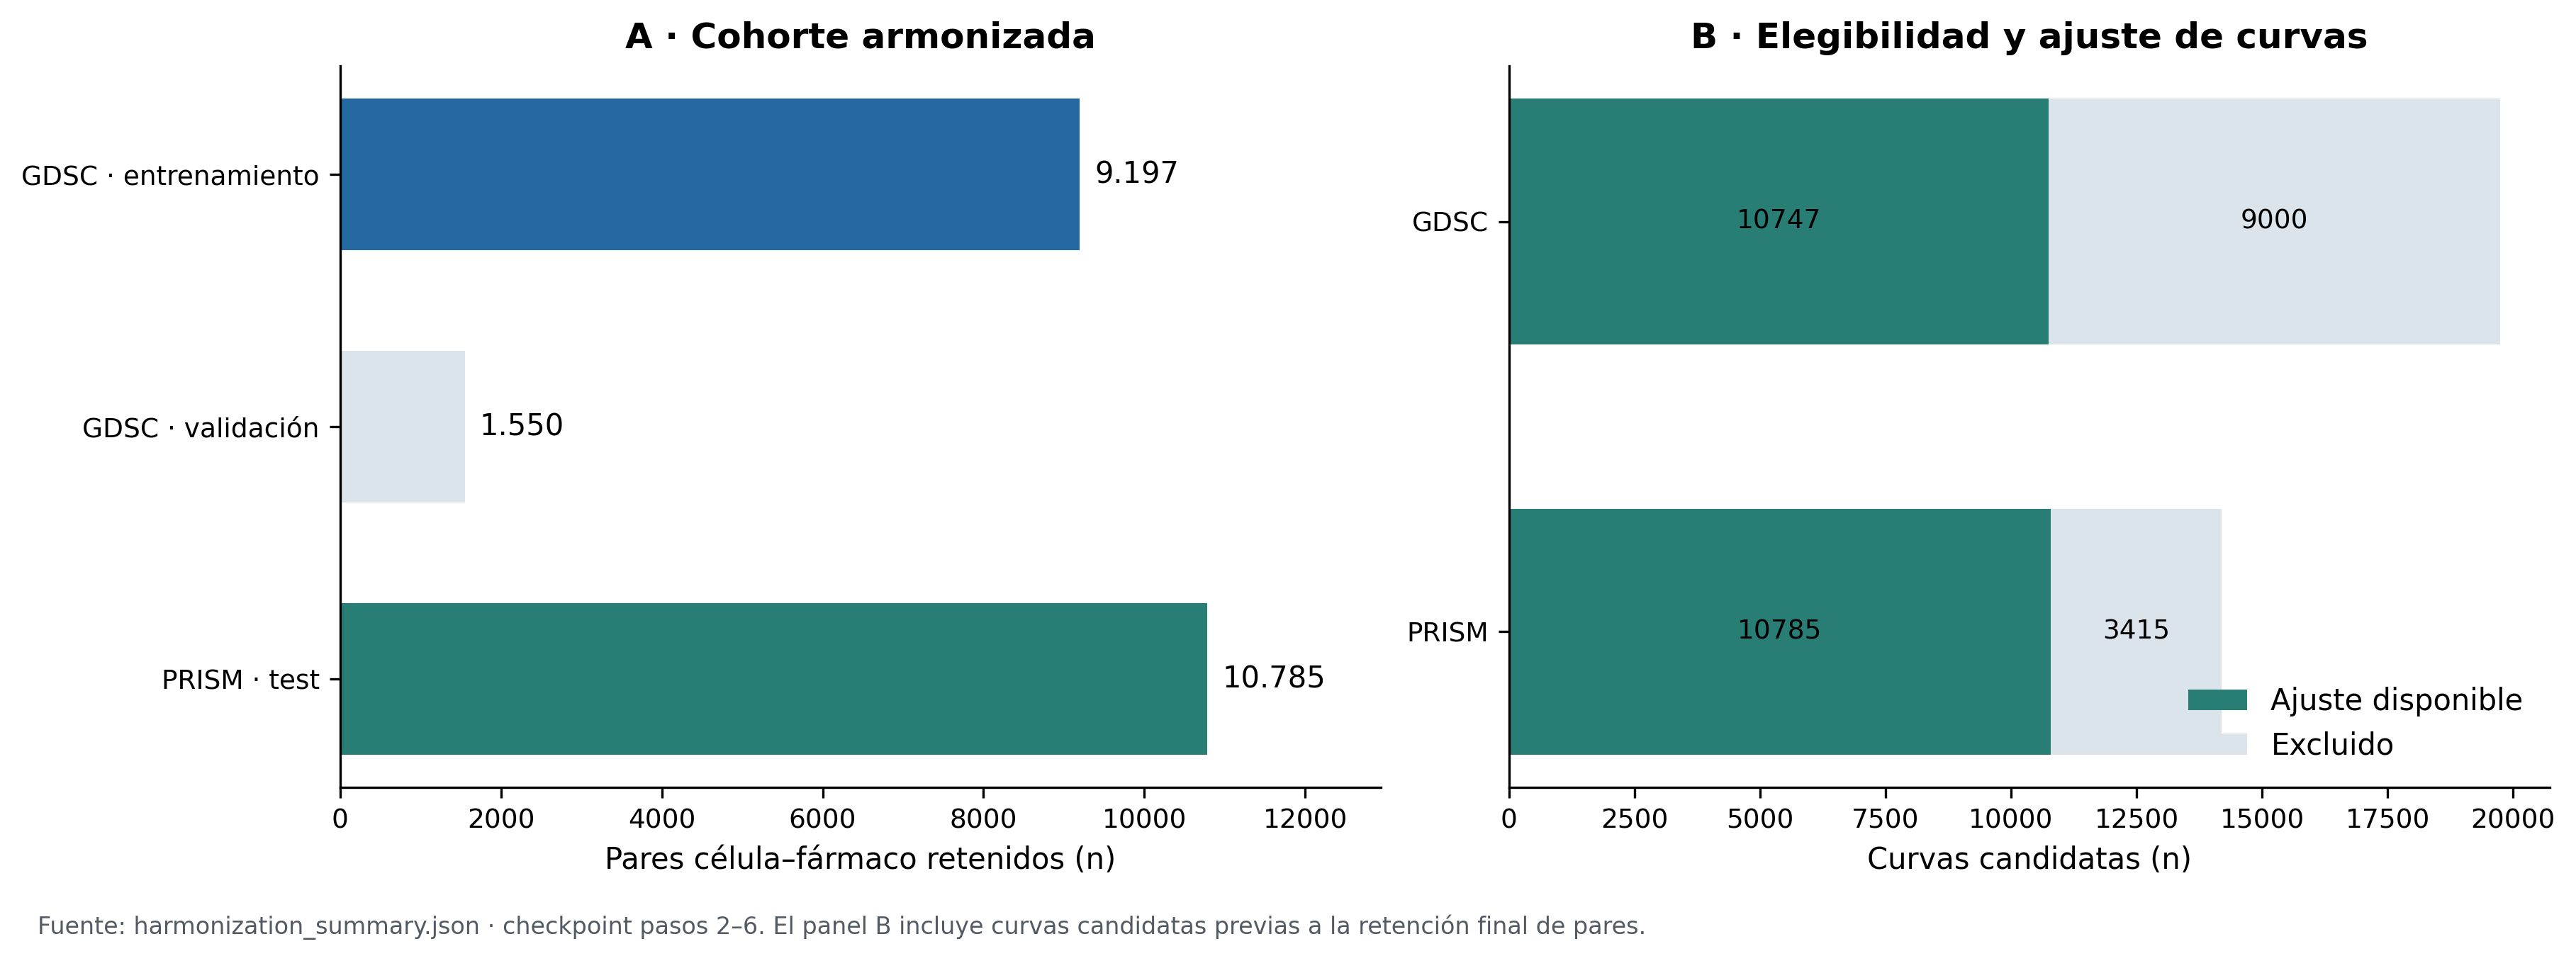

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.1), layout="constrained")
cohort = pd.DataFrame(harm["counts"])
labels = ["GDSC · entrenamiento", "GDSC · validación", "PRISM · test"]
bars = axes[0].barh(labels, cohort.n_pairs, color=[BLUE, PALE, TEAL], height=.6)
axes[0].invert_yaxis()
axes[0].bar_label(bars, labels=[f"{n:,}".replace(",", ".") for n in cohort.n_pairs], padding=5)
axes[0].set(xlabel="Pares célula–fármaco retenidos (n)", title="A · Cohorte armonizada")
axes[0].set_xlim(0, cohort.n_pairs.max() * 1.2)
status = pd.DataFrame(harm["fit_status"])
good = {"sigmoid_3pl", "constant_fallback", "flat"}
status["estado"] = status.status.map(lambda s: "Ajuste disponible" if s in good else "Excluido")
counts = status.groupby(["study", "estado"])["n"].sum().unstack(fill_value=0)
y = np.arange(2)
left = np.zeros(2)
for label, color in [("Ajuste disponible", TEAL), ("Excluido", PALE)]:
    values = counts.loc[["gdsc2", "prism"], label].to_numpy()
    bars = axes[1].barh(y, values, left=left, color=color, label=label, height=.6)
    axes[1].bar_label(bars, label_type="center", fmt="%d", fontsize=9)
    left += values
axes[1].set(yticks=y, yticklabels=["GDSC", "PRISM"], xlabel="Curvas candidatas (n)",
            title="B · Elegibilidad y ajuste de curvas")
axes[1].invert_yaxis()
axes[1].legend(frameon=False, loc="lower right")
finish(fig, "01_cohortes", "Fuente: harmonization_summary.json · checkpoint pasos 2–6. "
       "El panel B incluye curvas candidatas previas a la retención final de pares.")

## 2 · Generalización a fármacos nuevos

**RMSE menor es mejor**; R² normalizado mide la mejora sobre la referencia B0
ajustada con entrenamiento; Spearman por fármaco es la media no ponderada de
las correlaciones dentro de cada fármaco. Son preguntas diferentes.

Los puntos claros muestran los cinco folds y el punto grande su media
**no ponderada**. La barra es ±1 desviación estándar entre folds, **no un
intervalo de confianza**. Los modelos se presentan por RMSE descriptivo;
el test no selecciona hiperparámetros. Grafos solos predicen un valor constante
por fármaco y su Spearman dentro del fármaco es indefinido: no equivale a cero.

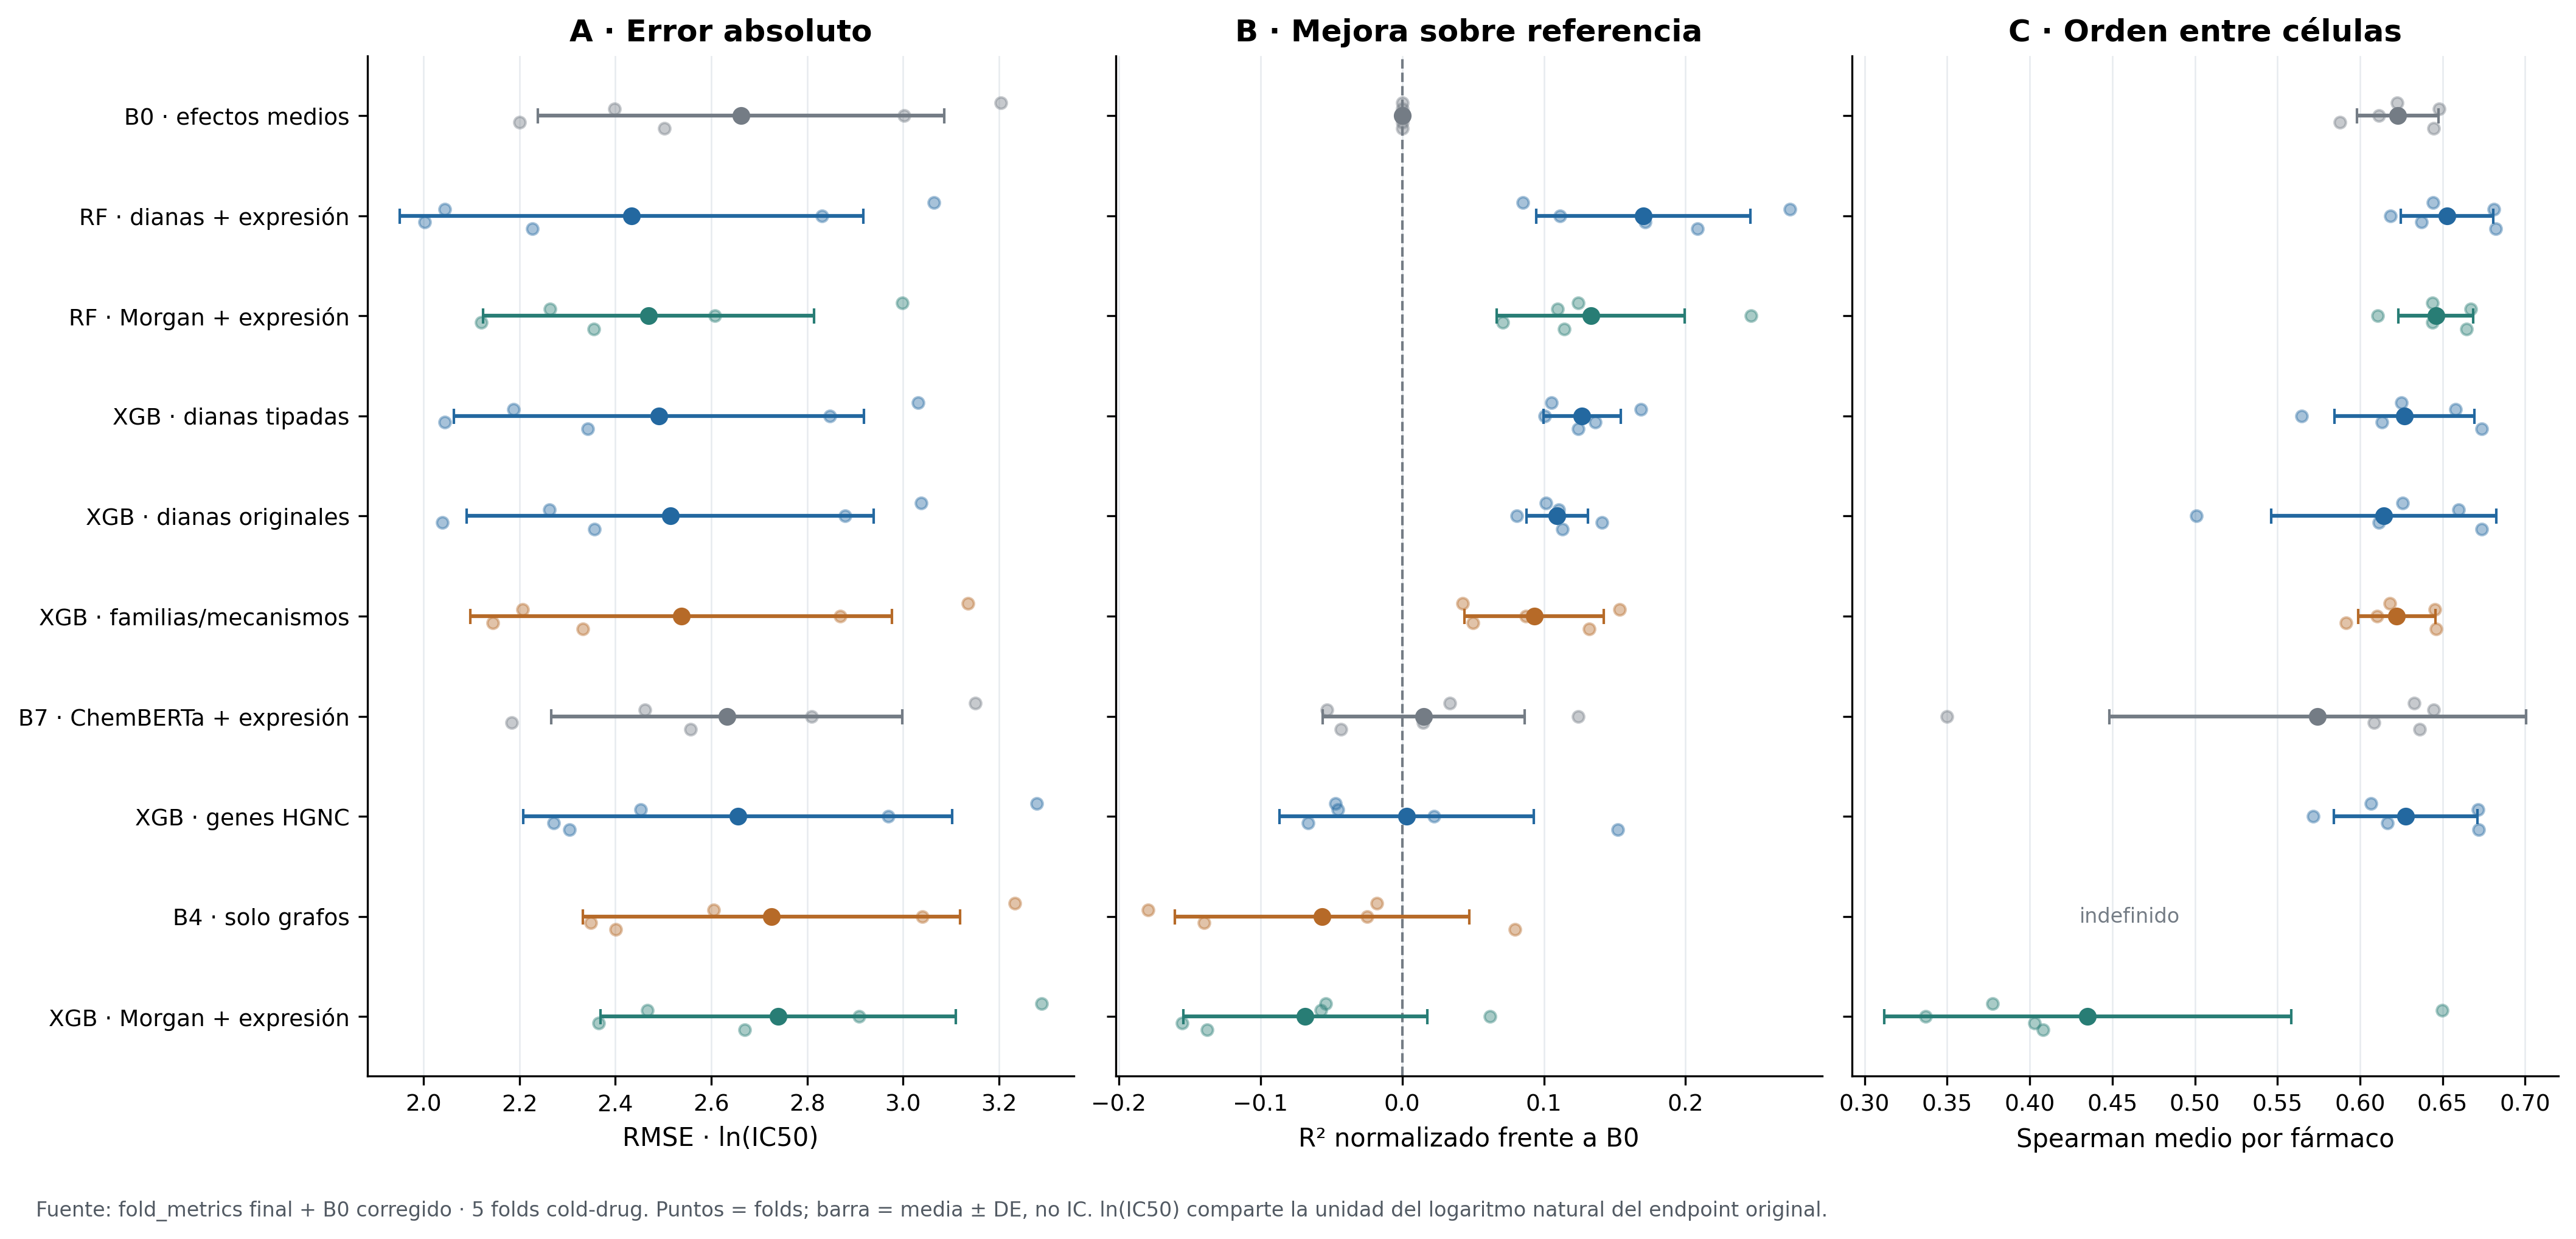

In [3]:
specs = [
    ("B0 · efectos medios", "B0", "mean_effects", "standard", GRAY),
    ("RF · dianas + expresión", "RF", "targets_expression_pca", "tuned", BLUE),
    ("RF · Morgan + expresión", "RF", "morgan_expression_pca", "tuned", TEAL),
    ("XGB · dianas tipadas", "B6", "targets_expression_pca", "targets_typed", BLUE),
    ("XGB · dianas originales", "B6", "targets_expression_pca", "standard", BLUE),
    ("XGB · familias/mecanismos", "B6", "targets_expression_pca", "targets_mechanisms", ORANGE),
    ("B7 · ChemBERTa + expresión", "B7", "pretrained_drug_expression_pca", "standard", GRAY),
    ("XGB · genes HGNC", "B6", "targets_expression_pca", "targets_genes", BLUE),
    ("B4 · solo grafos", "B4", "graph_only", "standard", ORANGE),
    ("XGB · Morgan + expresión", "B6", "morgan_expression_pca", "standard", TEAL),
]

def select(stage, model, variant):
    return test.loc[(test.stage == stage) & (test.model == model)
                    & (test.variant == variant)].sort_values("fold")

fig, axes = plt.subplots(1, 3, figsize=(14, 6.3), sharey=True, layout="constrained")
metrics = [("rmse", "RMSE · ln(IC50)", "A · Error absoluto"),
           ("r2_normalized", "R² normalizado frente a B0", "B · Mejora sobre referencia"),
           ("spearman_per_drug", "Spearman medio por fármaco", "C · Orden entre células")]
for y, (label, stage, model, variant, color) in enumerate(specs):
    frame = select(stage, model, variant)
    for ax, (metric, _, _) in zip(axes, metrics):
        values = frame[metric].dropna().to_numpy()
        if len(values):
            ax.scatter(values, y + np.linspace(-.13, .13, len(values)), s=20,
                       color=color, alpha=.4, zorder=2)
            ax.errorbar(values.mean(), y, xerr=values.std(ddof=1), fmt="o",
                        color=color, capsize=3, markersize=6, zorder=3)
        else:
            ax.text(.43, y, "indefinido", fontsize=8, color=GRAY, va="center")
for ax, (_, xlabel, title) in zip(axes, metrics):
    ax.set(xlabel=xlabel, title=title, yticks=np.arange(len(specs)))
    ax.grid(axis="x", color="#E7EBEF", lw=.6)
axes[0].set_yticklabels([s[0] for s in specs])
axes[0].invert_yaxis()
axes[1].axvline(0, color=GRAY, ls="--", lw=1)
finish(fig, "02_comparacion_principal", "Fuente: fold_metrics final + B0 corregido · "
       "5 folds cold-drug. Puntos = folds; barra = media ± DE, no IC. ln(IC50) comparte "
       "la unidad del logaritmo natural del endpoint original.")

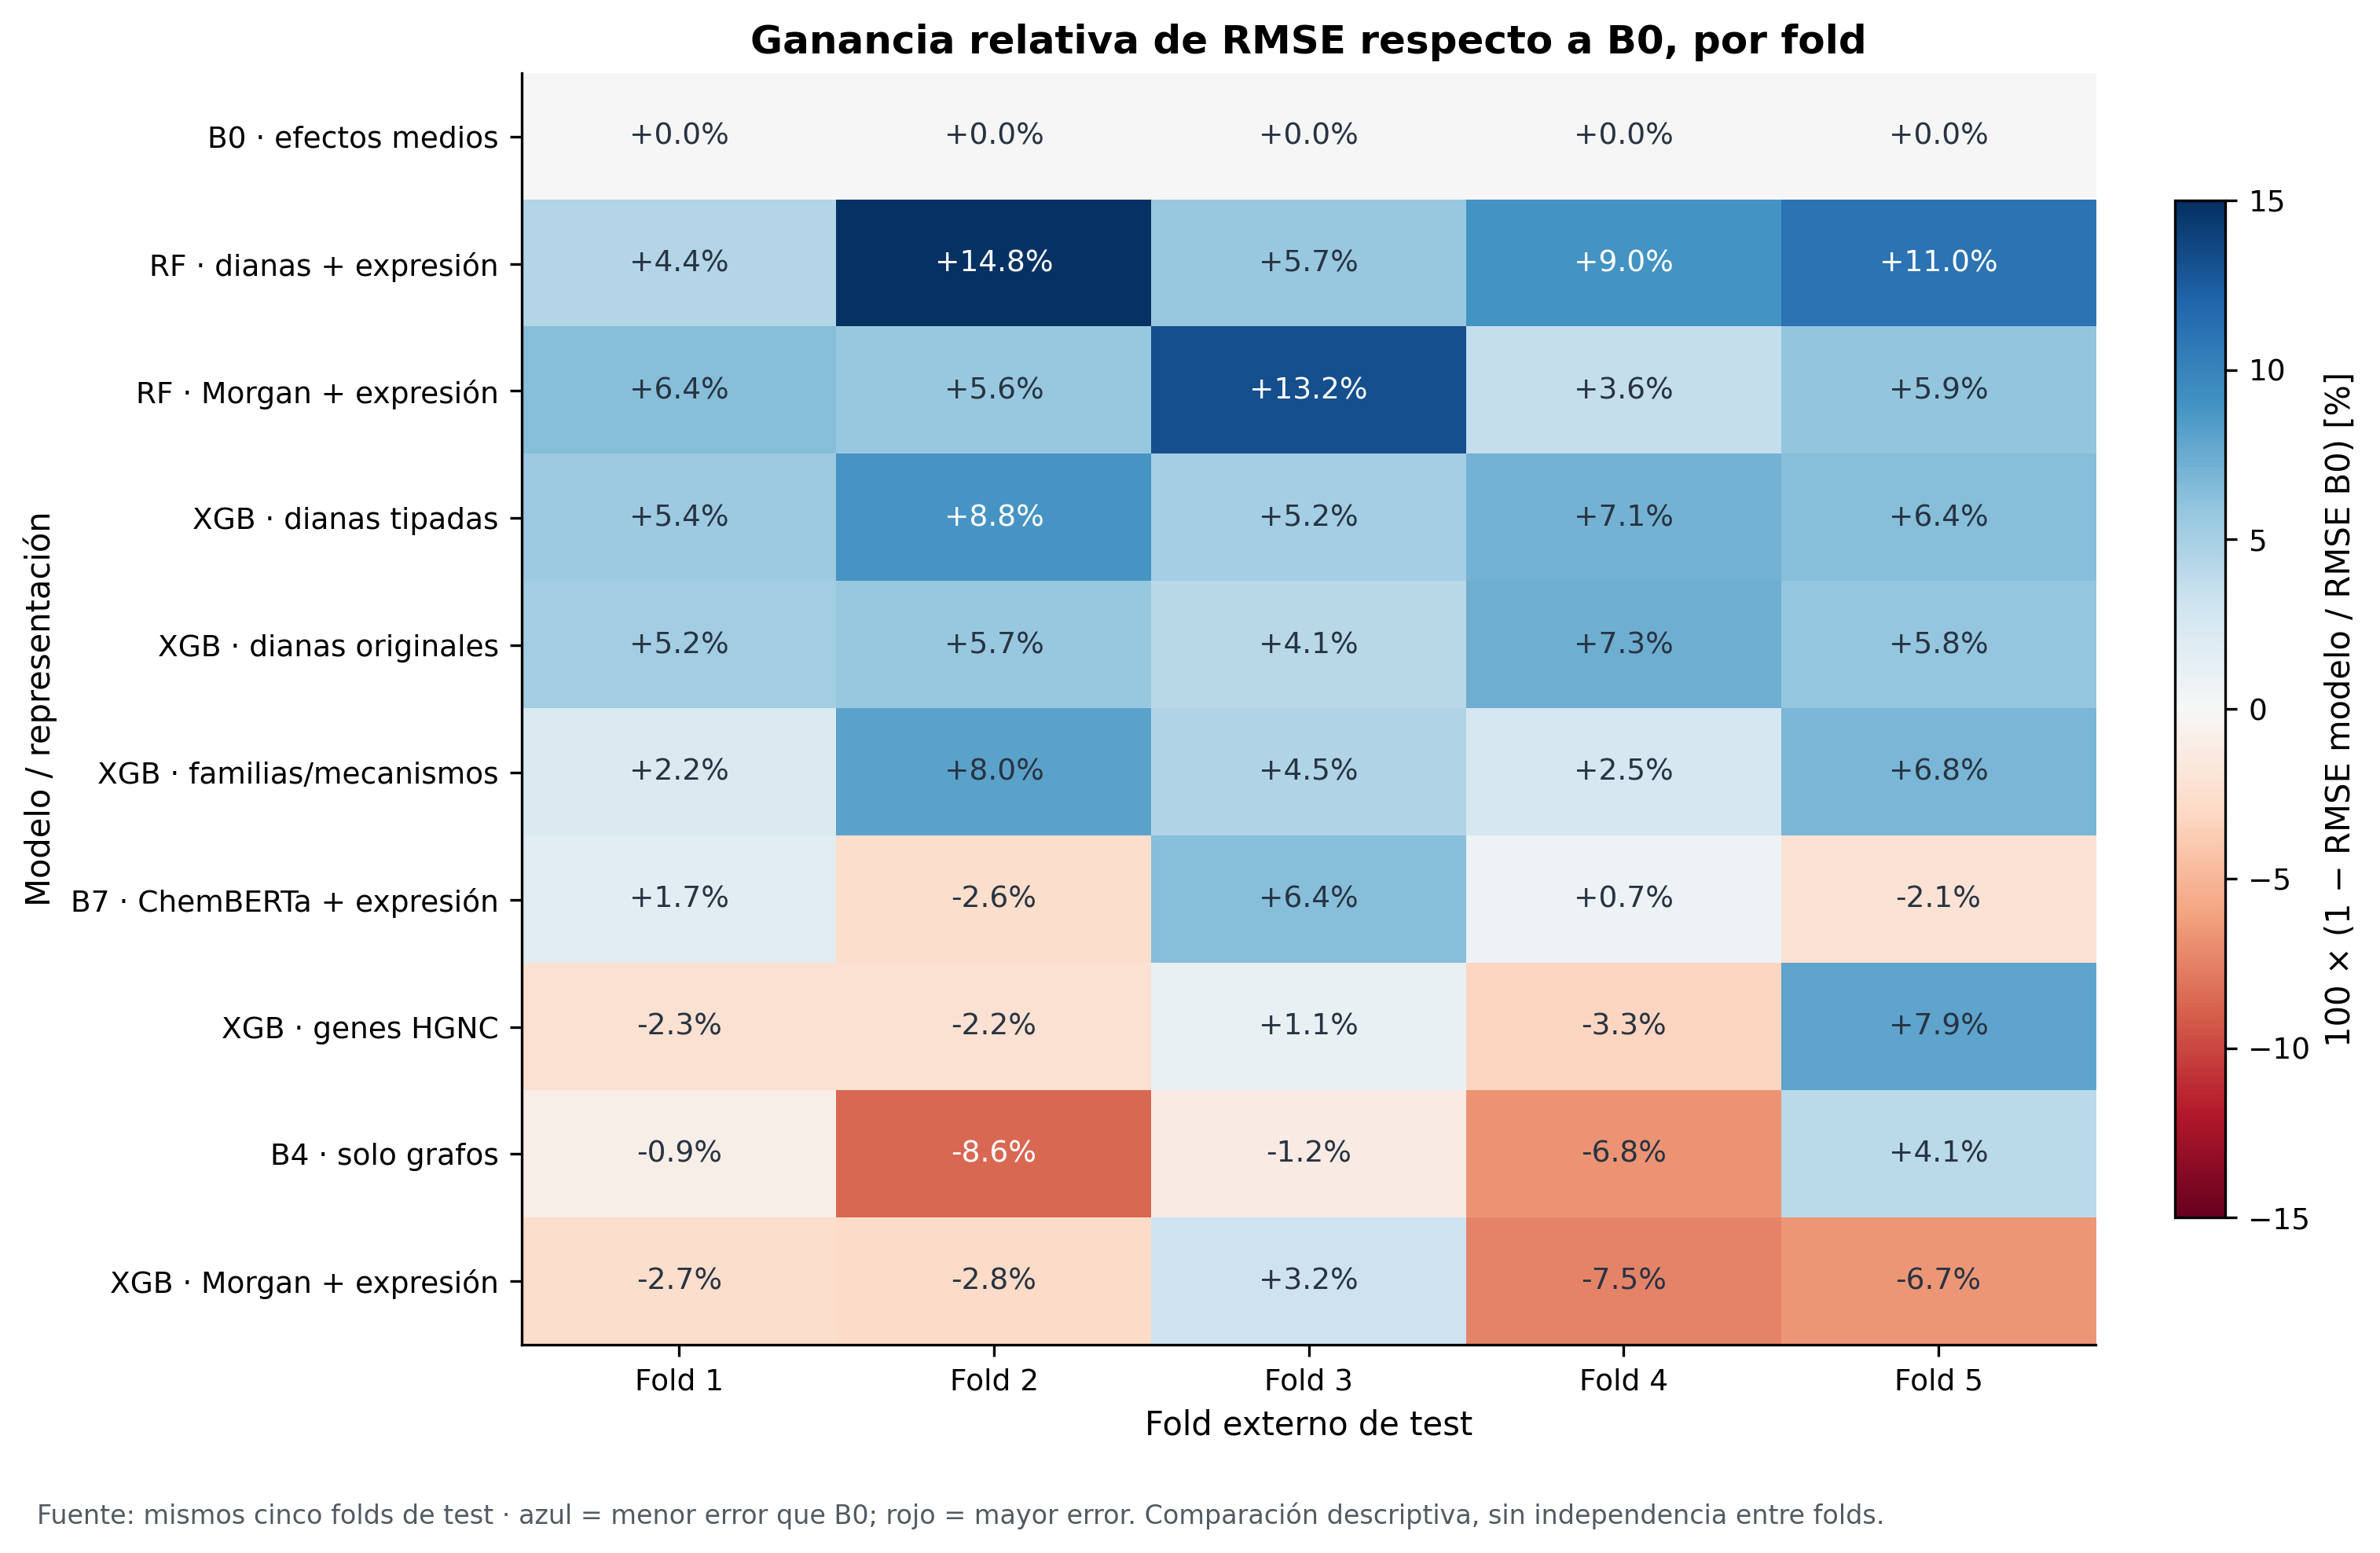

In [4]:
fig, ax = plt.subplots(figsize=(10, 6.1), layout="constrained")
base = baseline.set_index("fold").rmse.sort_index().to_numpy()
gains = np.array([100 * (1 - select(s, m, v).rmse.to_numpy() / base)
                  for _, s, m, v, _ in specs])
bound = max(15, np.ceil(np.abs(gains).max()))
im = ax.imshow(gains, cmap="RdBu", vmin=-bound, vmax=bound, aspect="auto")
for i in range(gains.shape[0]):
    for j in range(5):
        ax.text(j, i, f"{gains[i,j]:+.1f}%", ha="center", va="center",
                color="white" if abs(gains[i,j]) > bound*.55 else "#283442", fontsize=9)
ax.set(xticks=range(5), xticklabels=[f"Fold {f+1}" for f in range(5)],
       yticks=range(len(specs)), yticklabels=[s[0] for s in specs],
       xlabel="Fold externo de test", ylabel="Modelo / representación",
       title="Ganancia relativa de RMSE respecto a B0, por fold")
fig.colorbar(im, ax=ax, label="100 × (1 − RMSE modelo / RMSE B0) [%]", shrink=.8)
finish(fig, "03_ganancia_por_fold", "Fuente: mismos cinco folds de test · "
       "azul = menor error que B0; rojo = mayor error. Comparación descriptiva, sin independencia entre folds.")

### Predicciones fuera de muestra: todos los pares, sin selección estética

Los mapas usan los **149.364 pares de test**, exactamente una vez por modelo,
sin muestreo ni recorte de extremos. Los tres paneles comparten ejes, bins y
escala de color logarítmica. La diagonal representa predicción exacta.
El RMSE de estos paneles se calcula agrupando todos los pares; difiere de la
media no ponderada de RMSE por fold presentada arriba.

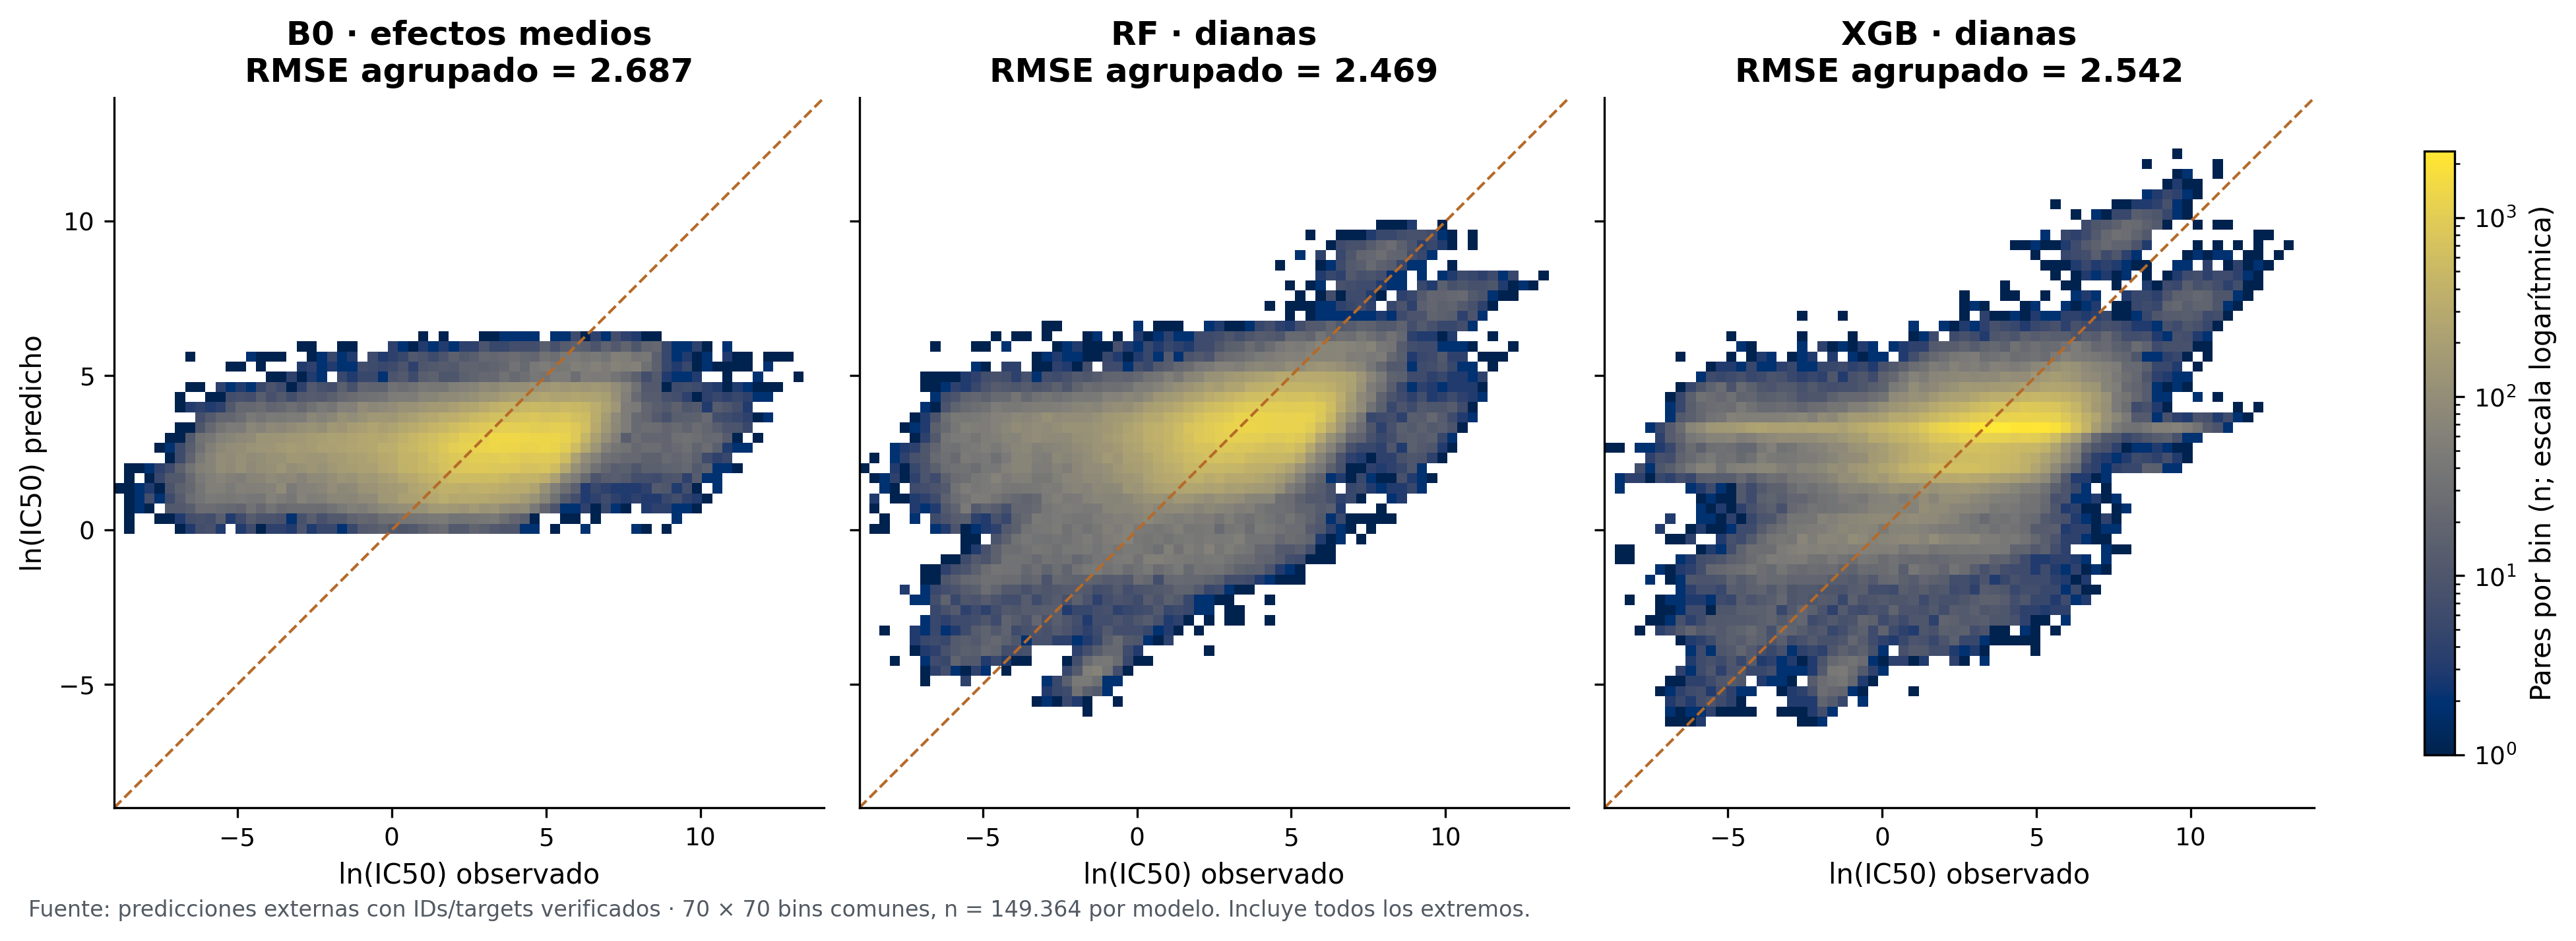

In [5]:
density = snapshot["prediction_density"]
edges = np.array(density["edges"])
maxcount = max(np.array(x["counts"]).max() for x in density["models"].values())
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True,
                         layout="constrained")
for ax, name, label in zip(axes, ["B0", "RF_targets", "XGB_targets"],
                          ["B0 · efectos medios", "RF · dianas", "XGB · dianas"]):
    values = density["models"][name]
    grid = np.array(values["counts"]).T
    im = ax.pcolormesh(edges, edges, np.ma.masked_equal(grid, 0), cmap="cividis",
                      norm=LogNorm(vmin=1, vmax=maxcount), rasterized=True)
    ax.plot([edges[0], edges[-1]], [edges[0], edges[-1]], color=ORANGE, ls="--", lw=1)
    ax.set(xlabel="ln(IC50) observado", title=f"{label}\nRMSE agrupado = {values['pooled_rmse']:.3f}",
           aspect="equal")
axes[0].set_ylabel("ln(IC50) predicho")
fig.colorbar(im, ax=axes, label="Pares por bin (n; escala logarítmica)", shrink=.85)
finish(fig, "04_predicciones_test", "Fuente: predicciones externas con IDs/targets verificados · "
       "70 × 70 bins comunes, n = 149.364 por modelo. Incluye todos los extremos.")

## 3 · Ajuste en validación y magnitud de la evidencia

### Selección del Random Forest
Cuatro candidatos por representación y fold: `max_features` ∈ {sqrt, 0,1},
`min_samples_leaf` ∈ {5, 20}, 200 árboles. Cada celda muestra **ΔRMSE de
validación respecto al mejor candidato del mismo fold**; el asterisco identifica
el mínimo. Estos colores no usan resultados de test.

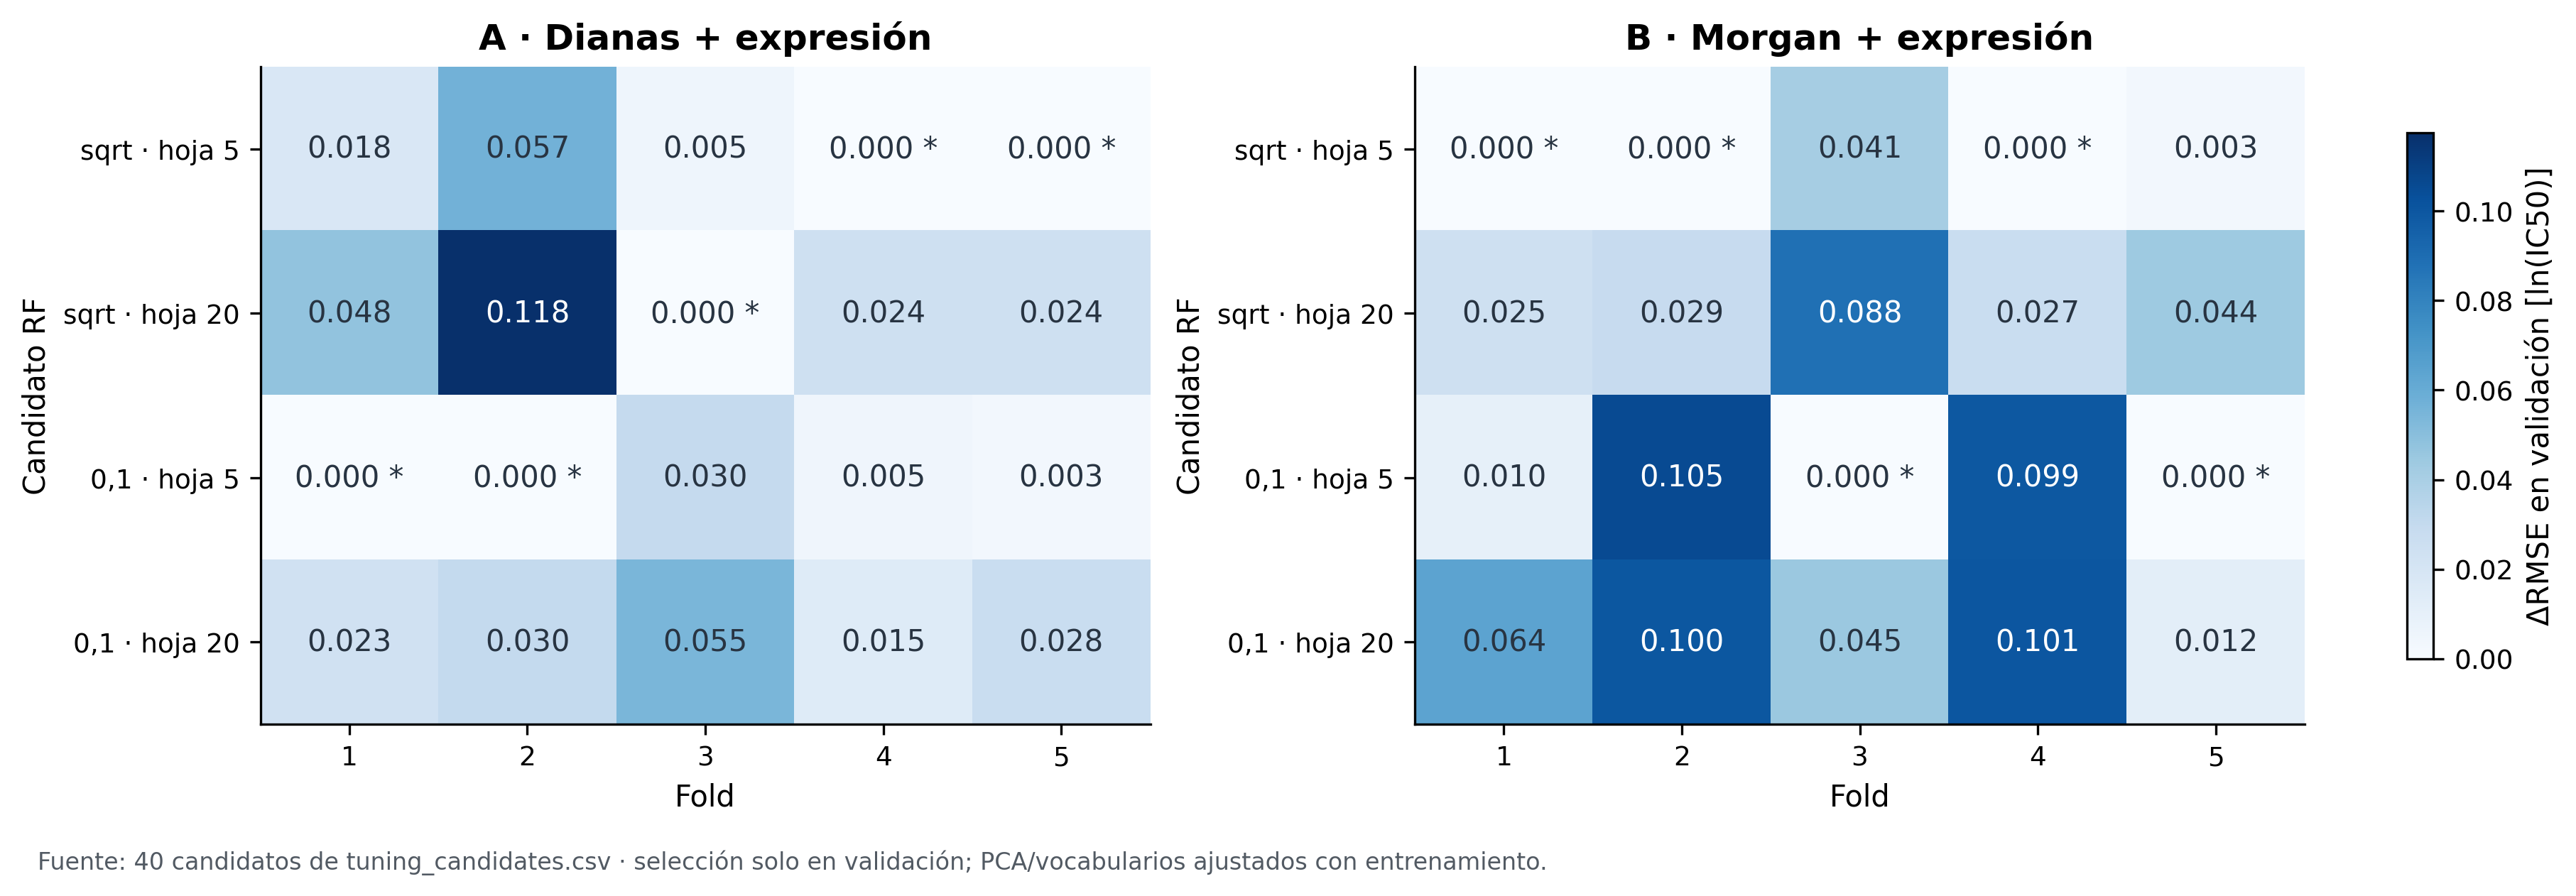

In [6]:
tuning = pd.DataFrame(snapshot["rf_validation_tuning"])
candidates = ["features=sqrt; leaf=5", "features=sqrt; leaf=20",
              "features=0.1; leaf=5", "features=0.1; leaf=20"]
matrices = []
for model in ["targets_expression_pca", "morgan_expression_pca"]:
    mat = tuning.loc[tuning.model.eq(model)].pivot(index="candidate", columns="fold",
                                                  values="validation_rmse").reindex(candidates)
    matrices.append(mat - mat.min(axis=0))
vmax = max(float(m.to_numpy().max()) for m in matrices)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, mat, title in zip(axes, matrices, ["A · Dianas + expresión", "B · Morgan + expresión"]):
    im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    for i in range(4):
        for j in range(5):
            value = mat.iloc[i,j]
            ax.text(j, i, f"{value:.3f}" + (" *" if abs(value)<1e-12 else ""),
                    ha="center", va="center", color="white" if value>vmax*.55 else "#283442")
    ax.set(xticks=range(5), xticklabels=[f"{f+1}" for f in range(5)],
           yticks=range(4), yticklabels=["sqrt · hoja 5", "sqrt · hoja 20", "0,1 · hoja 5", "0,1 · hoja 20"],
           xlabel="Fold", ylabel="Candidato RF", title=title)
fig.colorbar(im, ax=axes, label="ΔRMSE en validación [ln(IC50)]", shrink=.8)
finish(fig, "05_rf_ajuste_validacion", "Fuente: 40 candidatos de tuning_candidates.csv · "
       "selección solo en validación; PCA/vocabularios ajustados con entrenamiento.")

### Bootstrap pareado por fármaco

Los intervalos del 95 % corresponden al **cambio de RMSE frente a B0**, con
2.000 remuestreos pareados de fármacos dentro de cada fold. Valores negativos
favorecen al modelo. Condicionan en modelos ya ajustados, no incluyen el
reentrenamiento y no convierten los folds en estudios independientes.
Se muestran tres comparaciones principales; el inventario descargable del
final conserva las **105 comparaciones**, incluidas todas las variantes.

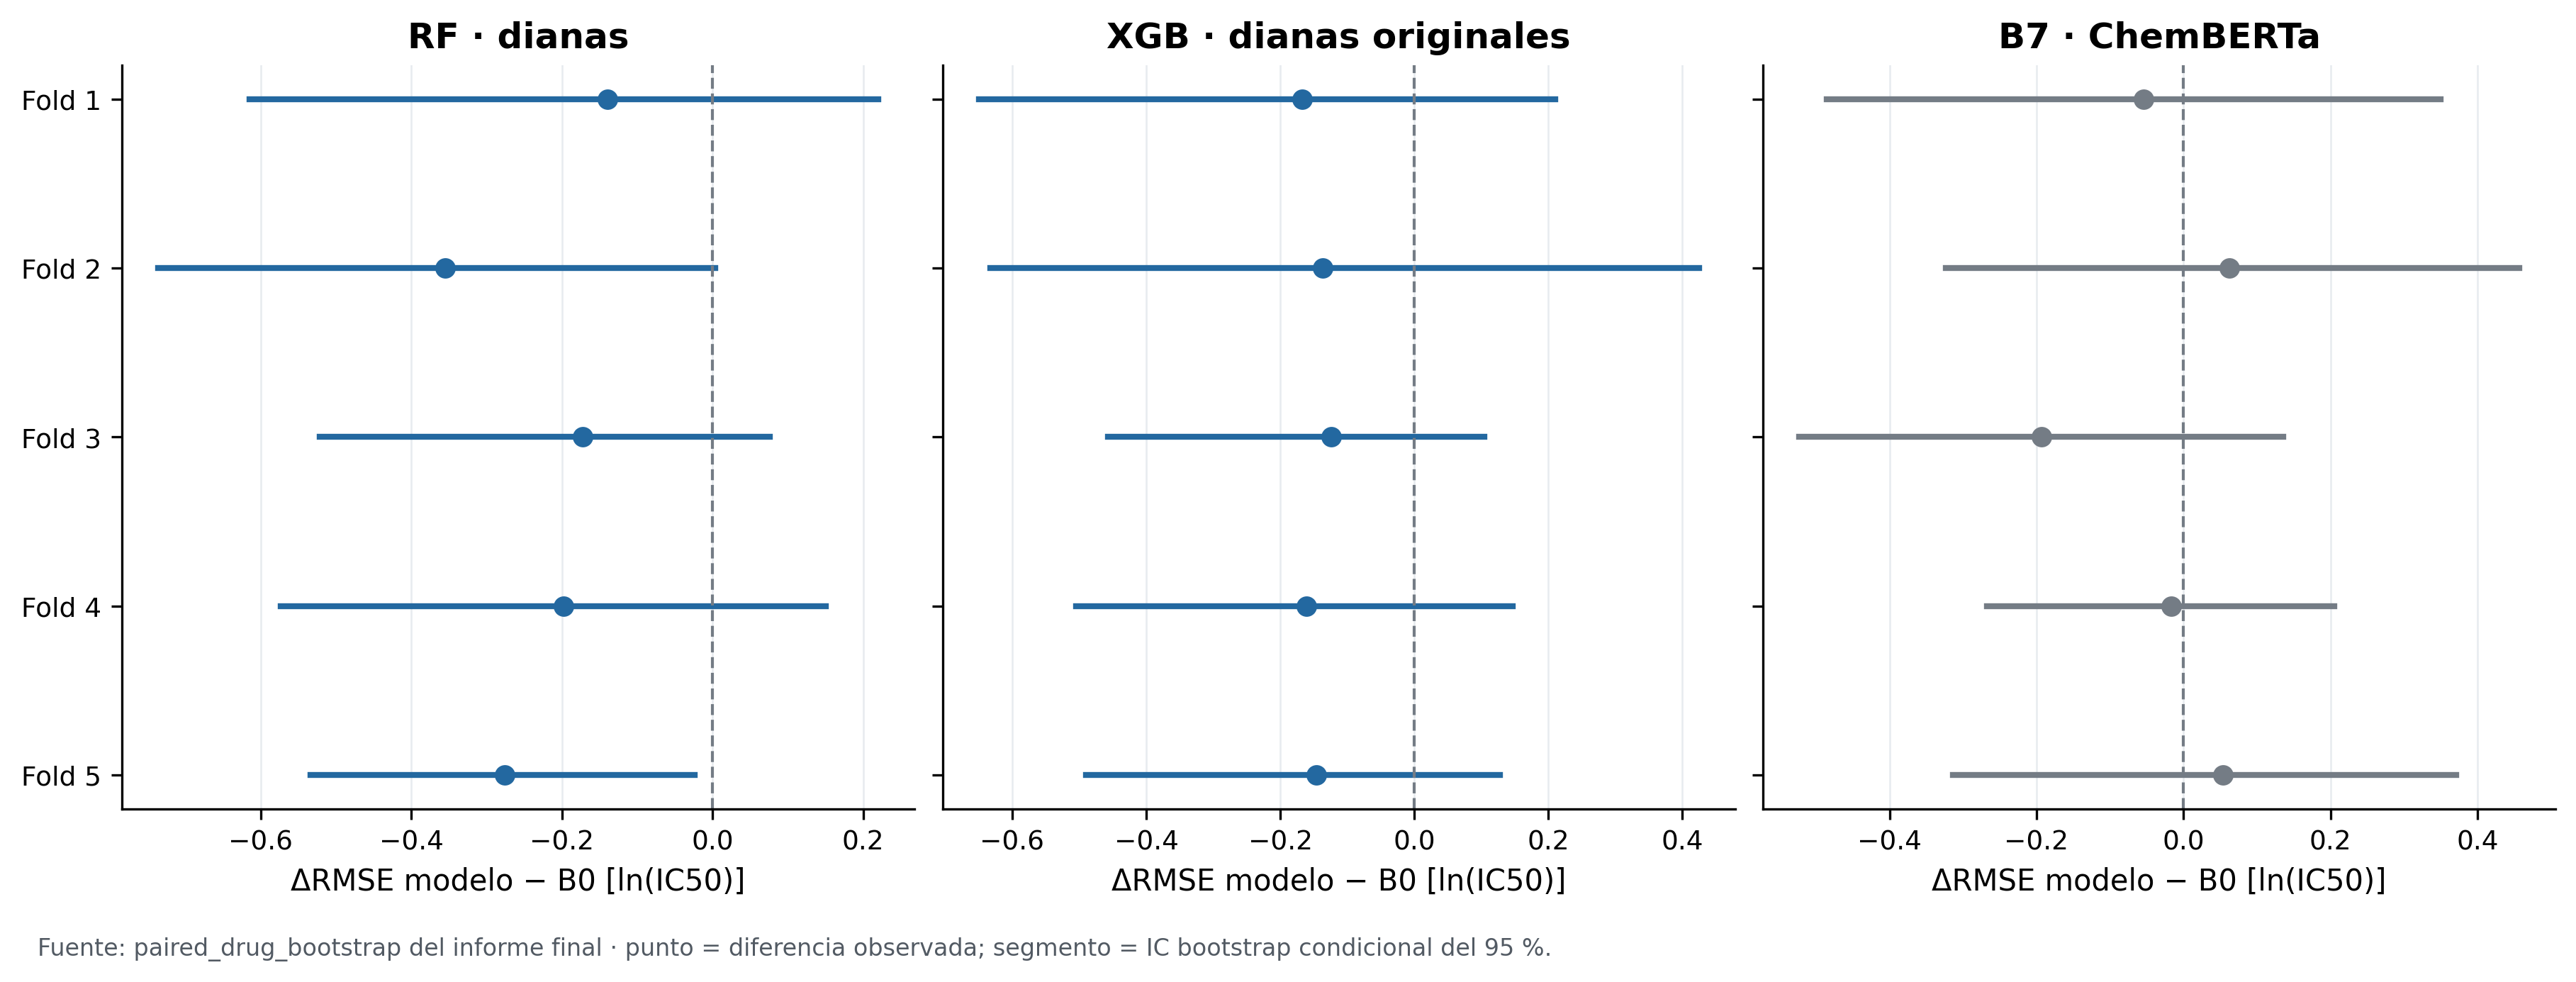

In [7]:
boot = pd.DataFrame(report["paired_drug_bootstrap"])
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True, layout="constrained")
for ax, stage, model, title, color in [
    (axes[0], "RF", "targets_expression_pca", "RF · dianas", BLUE),
    (axes[1], "B6", "targets_expression_pca", "XGB · dianas originales", BLUE),
    (axes[2], "B7", "pretrained_drug_expression_pca", "B7 · ChemBERTa", GRAY),
]:
    variant = "tuned" if stage == "RF" else "standard"
    data = boot.loc[(boot.stage == stage) & (boot.model == model) & (boot.variant == variant)]
    data = data.sort_values("fold")
    assert len(data) == 5
    for y, row in enumerate(data.itertuples()):
        ax.plot([row.ci95_low, row.ci95_high], [y,y], color=color, lw=2)
        ax.scatter(row.rmse_delta, y, color=color, s=35, zorder=3)
    ax.axvline(0, color=GRAY, ls="--", lw=1)
    ax.set(yticks=range(5), yticklabels=[f"Fold {i+1}" for i in range(5)],
           xlabel="ΔRMSE modelo − B0 [ln(IC50)]", title=title)
    ax.grid(axis="x", color="#E7EBEF", lw=.6)
axes[0].invert_yaxis()
finish(fig, "06_bootstrap_pareado", "Fuente: paired_drug_bootstrap del informe final · "
       "punto = diferencia observada; segmento = IC bootstrap condicional del 95 %.")

## 4 · Controles de representación y anotaciones

### Permutaciones consistentes por entidad

Se permuta el vector completo por célula o fármaco, con semillas 7, 13 y 42,
dentro de estratos de pertenencia a particiones. El mismo ID recibe el mismo
vector en todos sus pares. Los puntos son los cinco folds de cada ejecución;
la referencia conserva los mismos parámetros de ajuste. La degradación
diagnostica dependencia de la representación, no causalidad biológica.

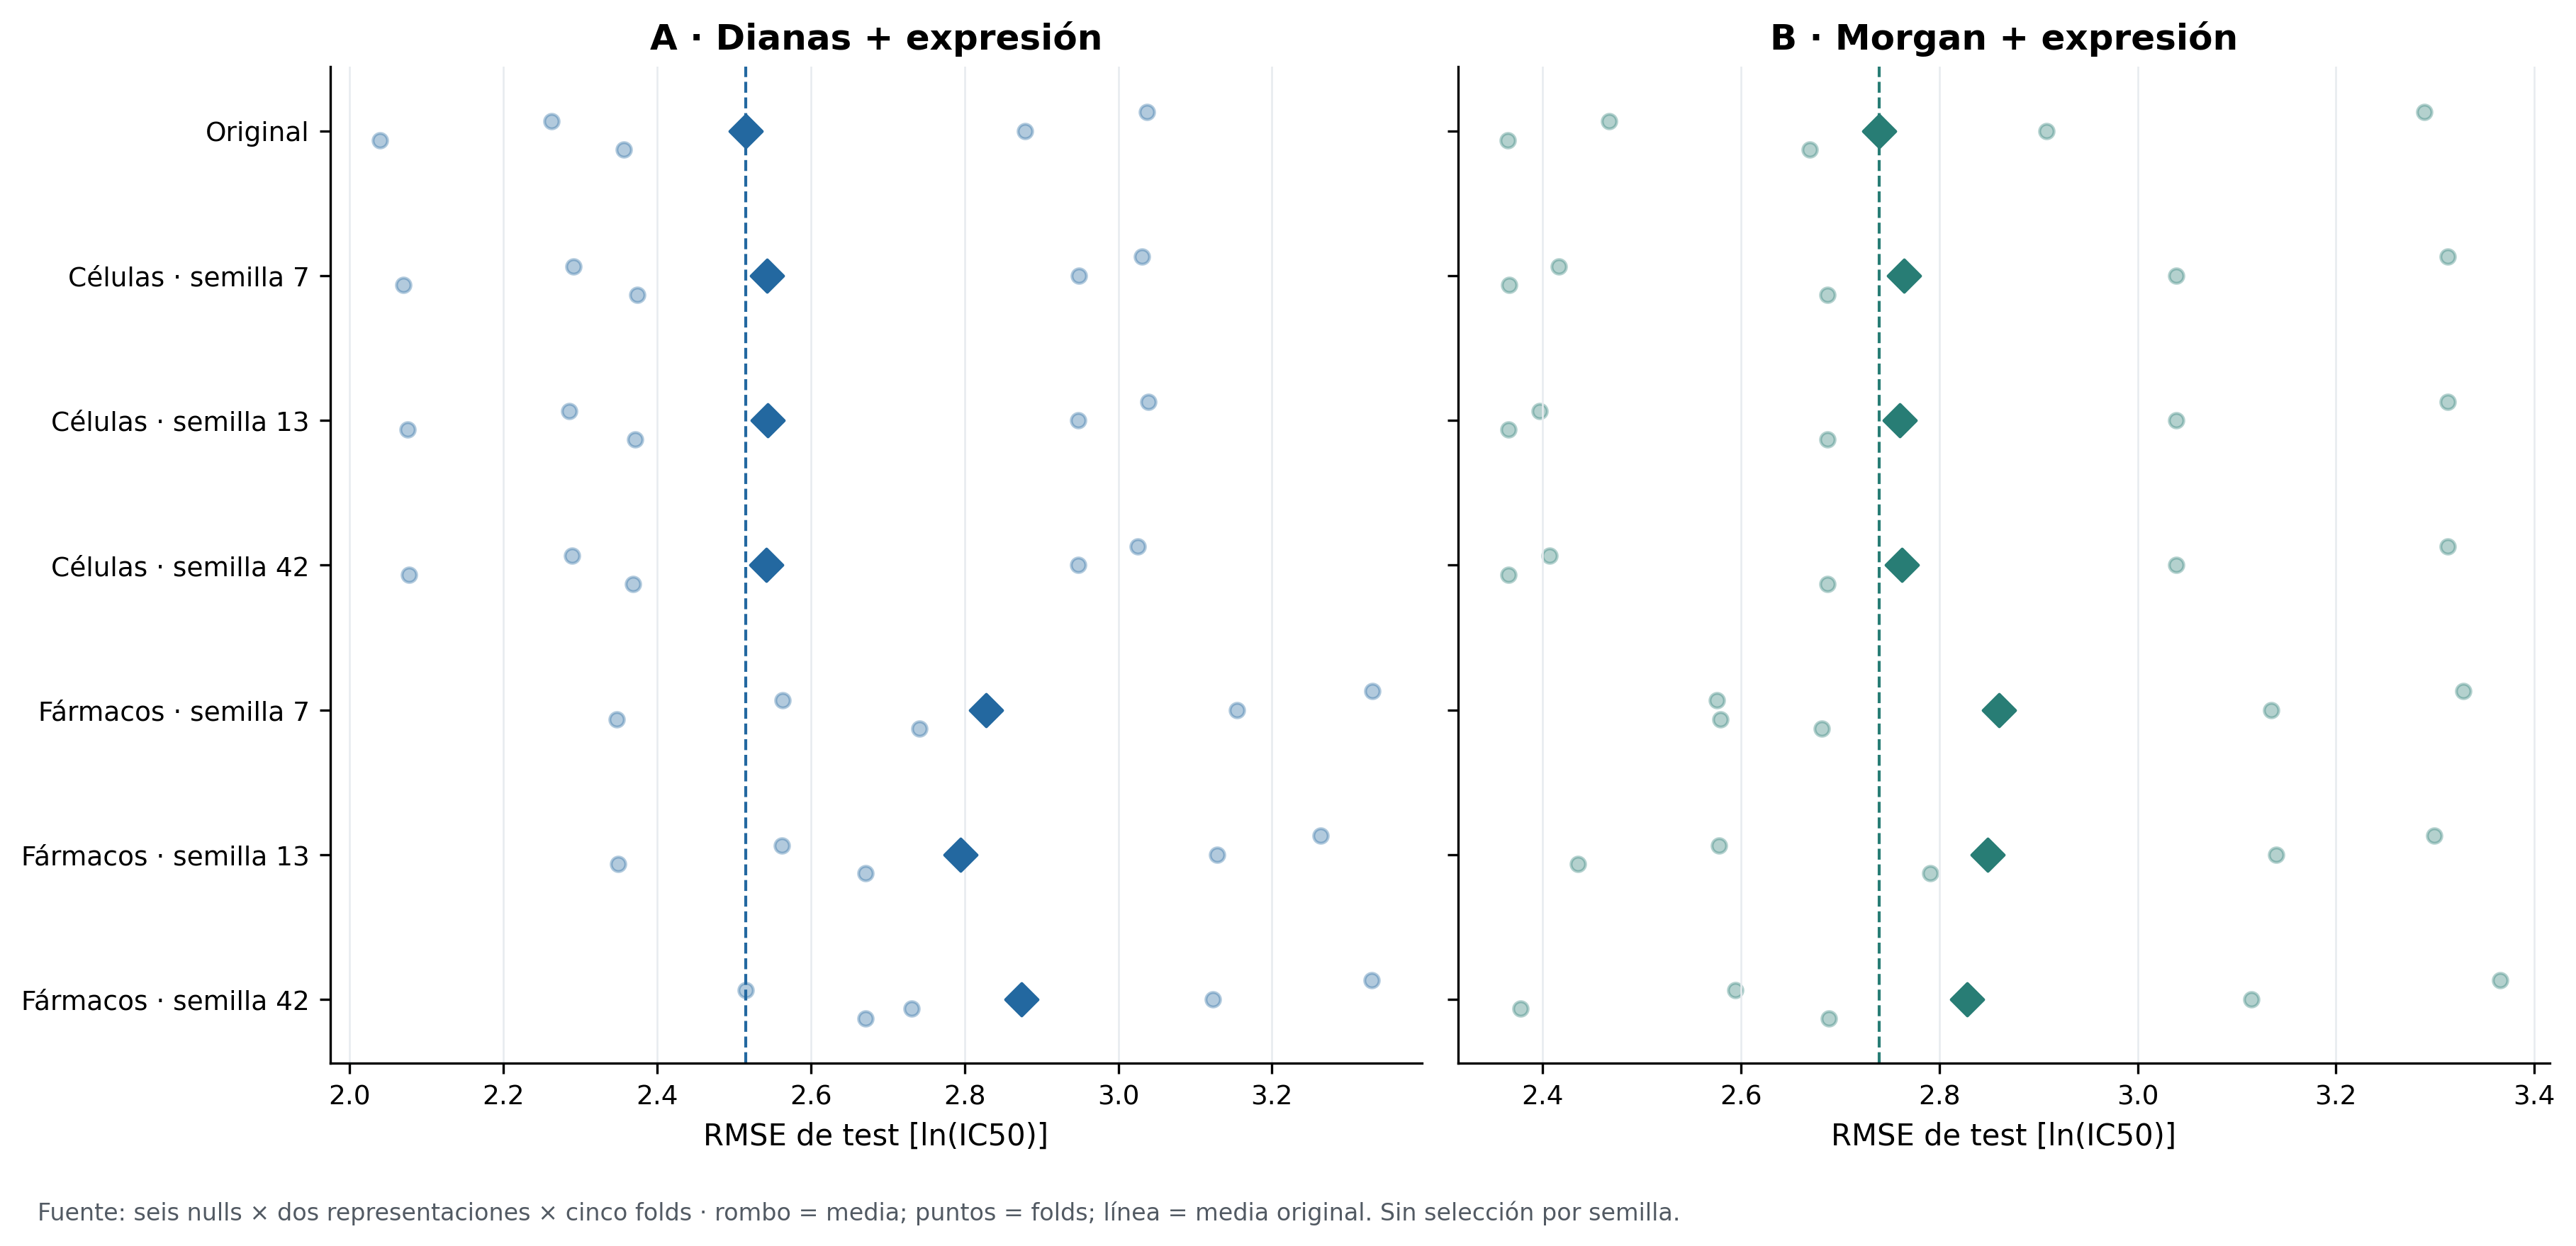

In [8]:
variants = ["standard", "cell_permuted_7", "cell_permuted_13", "cell_permuted_42",
            "drug_permuted_7", "drug_permuted_13", "drug_permuted_42"]
names = ["Original", "Células · semilla 7", "Células · semilla 13", "Células · semilla 42",
         "Fármacos · semilla 7", "Fármacos · semilla 13", "Fármacos · semilla 42"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True, layout="constrained")
for ax, model, title, color in zip(axes, ["targets_expression_pca", "morgan_expression_pca"],
                                  ["A · Dianas + expresión", "B · Morgan + expresión"], [BLUE, TEAL]):
    for y, variant in enumerate(variants):
        values = select("B6", model, variant).rmse.to_numpy()
        ax.scatter(values, y + np.linspace(-.13,.13,5), color=color, alpha=.35, s=24)
        ax.scatter(values.mean(), y, color=color, s=60, marker="D", zorder=3)
    ax.axvline(select("B6", model, "standard").rmse.mean(), color=color, ls="--", lw=1)
    ax.set(yticks=range(7), yticklabels=names, xlabel="RMSE de test [ln(IC50)]", title=title)
    ax.grid(axis="x", color="#E7EBEF", lw=.6)
axes[0].invert_yaxis()
finish(fig, "07_permutaciones", "Fuente: seis nulls × dos representaciones × cinco folds · "
       "rombo = media; puntos = folds; línea = media original. Sin selección por semilla.")

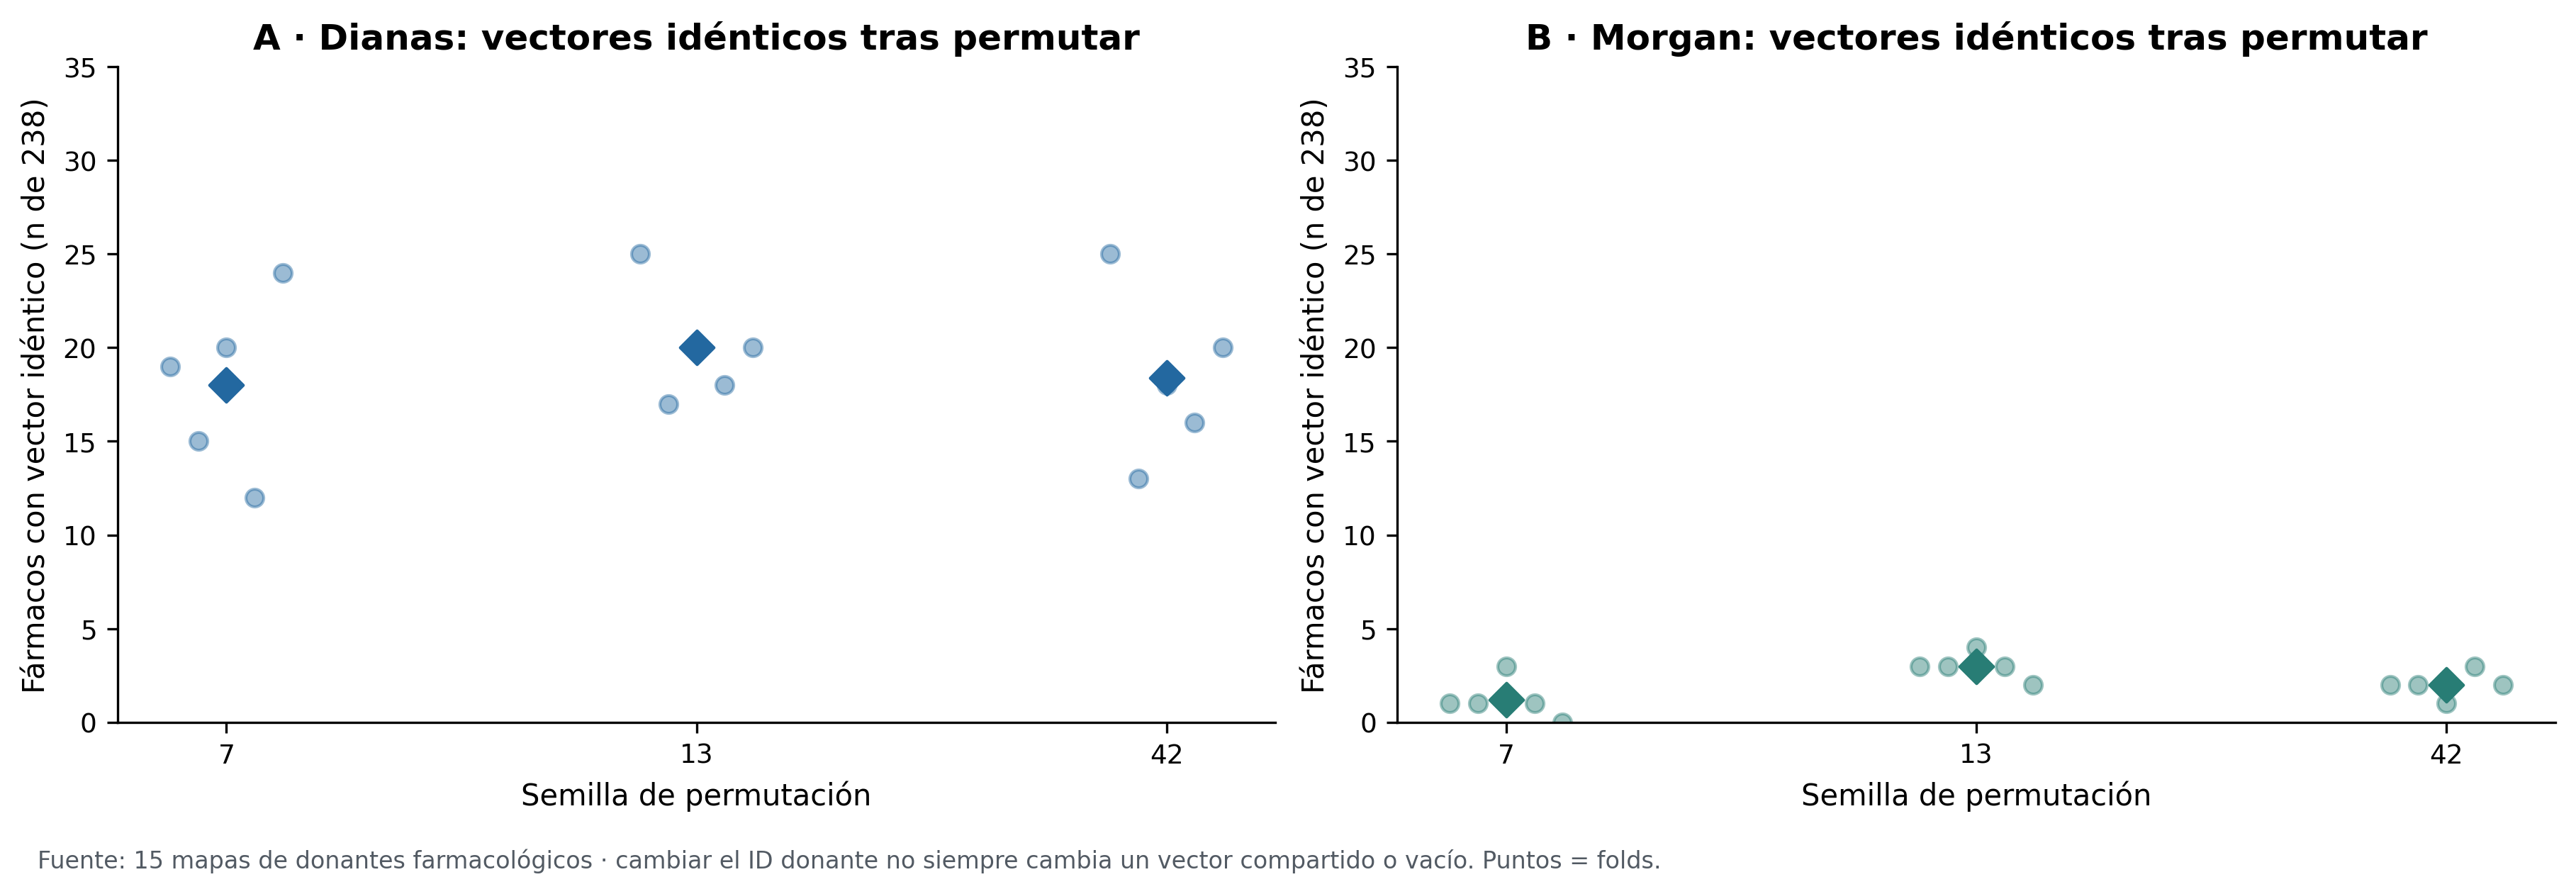

In [9]:
donors = pd.DataFrame(report["donor_diagnostics"])
drug = donors.loc[donors.block.eq("drug")]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, column, title, color in [
    (axes[0], "n_unchanged_target_vectors", "A · Dianas: vectores idénticos tras permutar", BLUE),
    (axes[1], "n_unchanged_morgan_vectors", "B · Morgan: vectores idénticos tras permutar", TEAL),
]:
    for x, seed in enumerate([7,13,42]):
        values = drug.loc[drug.seed.eq(seed), column].to_numpy()
        ax.scatter(x + np.linspace(-.12,.12,5), values, color=color, alpha=.45)
        ax.scatter(x, values.mean(), marker="D", s=65, color=color)
    ax.set(xticks=range(3), xticklabels=["7","13","42"], xlabel="Semilla de permutación",
           ylabel="Fármacos con vector idéntico (n de 238)", title=title, ylim=(0,35))
finish(fig, "08_fuerza_del_control", "Fuente: 15 mapas de donantes farmacológicos · "
       "cambiar el ID donante no siempre cambia un vector compartido o vacío. Puntos = folds.")

### Qué representan las dianas

La columna original mezcla genes, familias y mecanismos. La normalización
con HGNC conserva esas categorías y la ambigüedad; no expande familias en
genes supuestos. **159 de 238 fármacos** tienen al menos un gen resuelto.
Los recuentos de tokens son ocurrencias por fármaco, no genes únicos.
El alias HGNC es una resolución de nomenclatura, no evidencia de unión
experimental ni de selectividad por isoforma. La fecha de curación original
se desconoce. Las tres vistas mostradas se reentrenaron tras corregir la
prioridad de las etiquetas de familia.

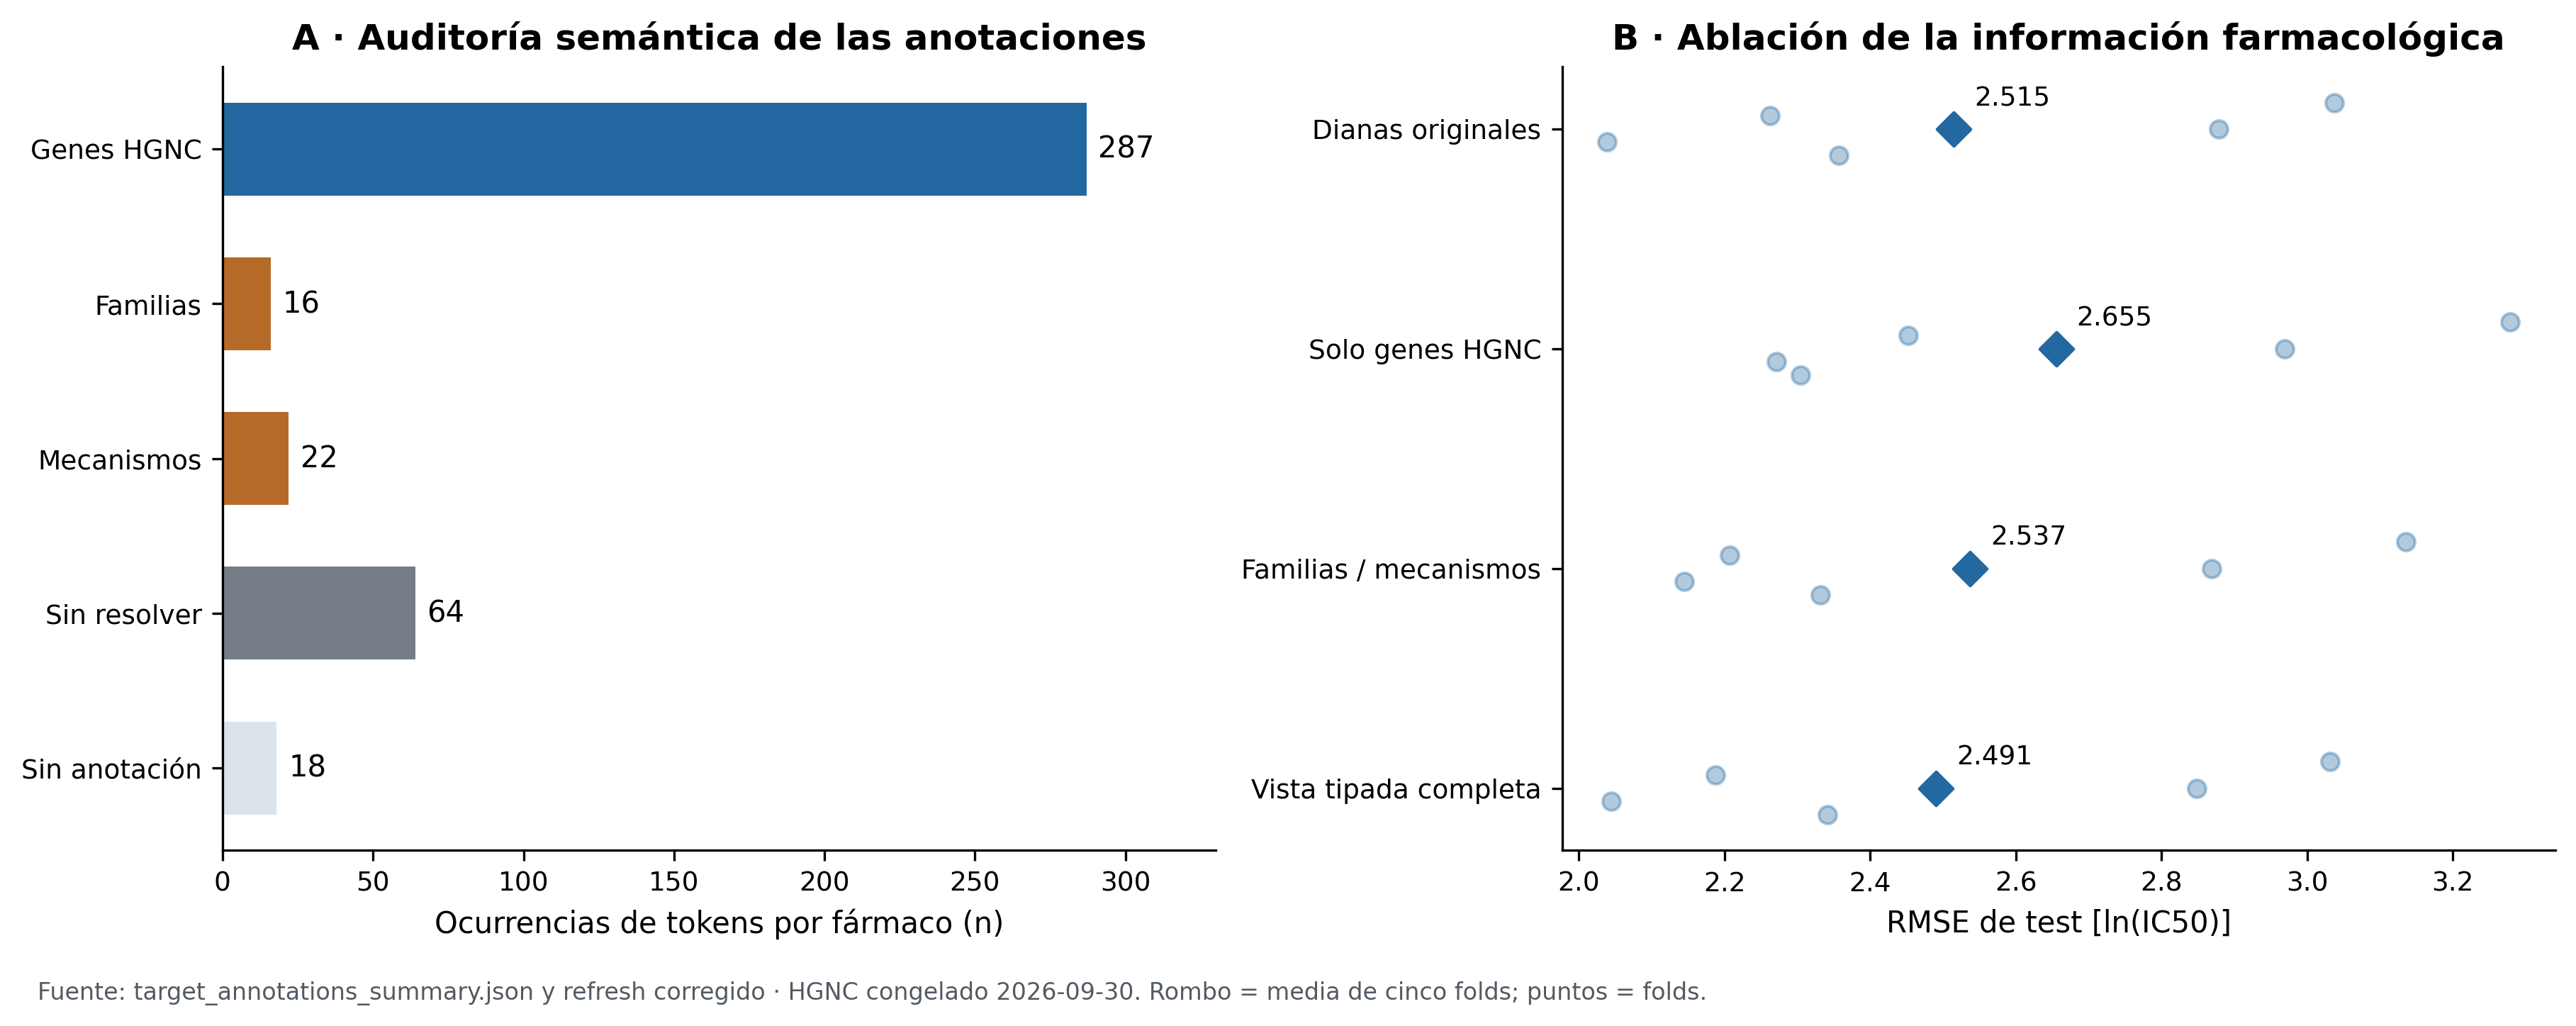

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
kinds = ["gene", "family", "mechanism", "unresolved", "missing"]
labels = ["Genes HGNC", "Familias", "Mecanismos", "Sin resolver", "Sin anotación"]
vals = [annotation["token_counts"].get(k,0) for k in kinds]
bars = axes[0].barh(labels, vals, color=[BLUE, ORANGE, ORANGE, GRAY, PALE], height=.6)
axes[0].bar_label(bars, padding=4)
axes[0].set(xlim=(0,max(vals)*1.15), xlabel="Ocurrencias de tokens por fármaco (n)",
            title="A · Auditoría semántica de las anotaciones")
axes[0].invert_yaxis()
views = [("Dianas originales", "standard"), ("Solo genes HGNC", "targets_genes"),
         ("Familias / mecanismos", "targets_mechanisms"), ("Vista tipada completa", "targets_typed")]
for y, (label, variant) in enumerate(views):
    values = select("B6", "targets_expression_pca", variant).rmse.to_numpy()
    axes[1].scatter(values, y + np.linspace(-.12,.12,5), color=BLUE, alpha=.35)
    axes[1].scatter(values.mean(), y, color=BLUE, s=65, marker="D")
    axes[1].annotate(f"{values.mean():.3f}", (values.mean(), y), xytext=(7,8),
                     textcoords="offset points", fontsize=9)
axes[1].set(yticks=range(4), yticklabels=[x[0] for x in views], xlabel="RMSE de test [ln(IC50)]",
            title="B · Ablación de la información farmacológica")
axes[1].invert_yaxis()
finish(fig, "09_anotaciones_y_vistas", "Fuente: target_annotations_summary.json y refresh corregido · "
       "HGNC congelado 2026-09-30. Rombo = media de cinco folds; puntos = folds.")

## 5 · Transferencia de GDSC a PRISM

### Concordancia de endpoints en los mismos pares

Los dos endpoints se comparan en **22 fármacos y 4.548 pares compartidos**.
Cada punto es un fármaco, con peso idéntico en la media; no se mezclan muestras
con diferentes soportes. La armonización aumenta ligeramente la correlación
media de rangos, pero también aumenta la discrepancia absoluta media entre
ensayos. Por tanto, estandarizar la integración de dosis no elimina el cambio
de plataforma, exposición o medición.

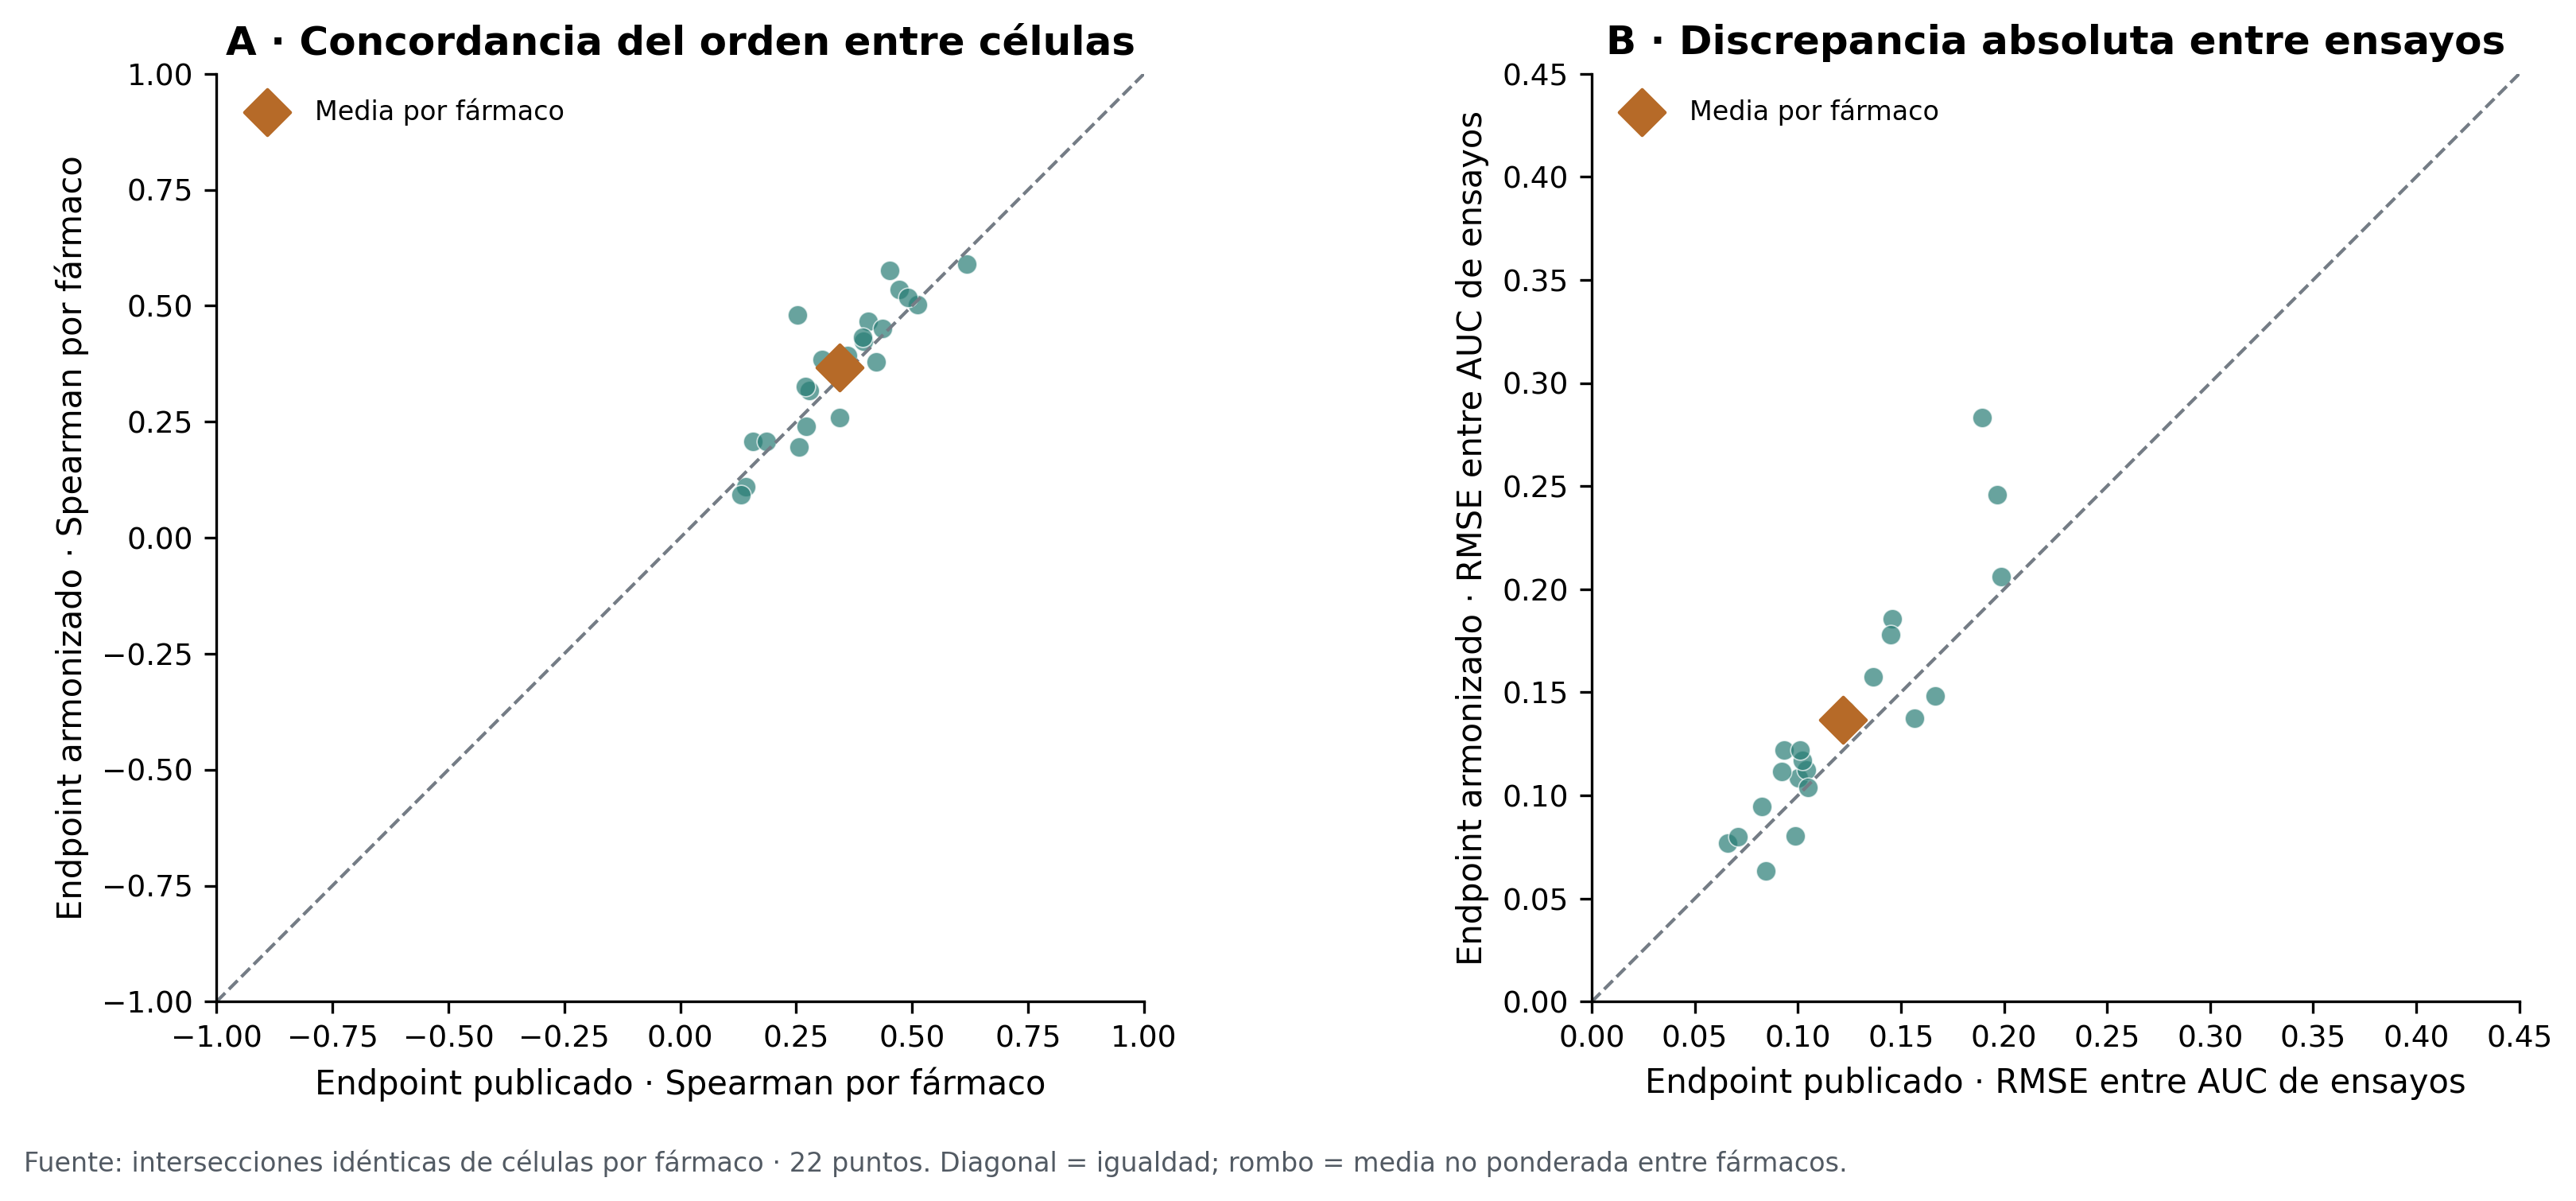

,endpoint,n_drugs,n_matched_pairs,pearson_mean,spearman_mean,mean_shift,mean_drug_auc_discrepancy
0,harmonized,22,4548,0.450,0.367,-0.0045,0.1369
1,published,22,4548,0.395,0.343,+0.0079,0.1219


In [11]:
concordance = pd.DataFrame(report["endpoint_concordance"]["paired_drugs"])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), layout="constrained")
for ax, metric, title, unit, limits in [
    (axes[0], "spearman", "A · Concordancia del orden entre células", "Spearman por fármaco", (-1,1)),
    (axes[1], "rmse_between_published_auc", "B · Discrepancia absoluta entre ensayos", "RMSE entre AUC de ensayos", (0,.45)),
]:
    p = concordance.pivot(index="drug_id", columns="endpoint", values=metric).dropna()
    ax.scatter(p.published, p.harmonized, color=TEAL, s=35, alpha=.7, edgecolors="white", lw=.4)
    ax.scatter(p.published.mean(), p.harmonized.mean(), color=ORANGE, marker="D", s=95,
               label="Media por fármaco", zorder=3)
    ax.plot(limits, limits, color=GRAY, ls="--", lw=1)
    ax.set(xlim=limits, ylim=limits, xlabel=f"Endpoint publicado · {unit}",
           ylabel=f"Endpoint armonizado · {unit}", title=title, aspect="equal")
    ax.legend(frameon=False, fontsize=8)
finish(fig, "10_concordancia_ensayos", "Fuente: intersecciones idénticas de células por fármaco · "
       "22 puntos. Diagonal = igualdad; rombo = media no ponderada entre fármacos.")
display(style_table(pd.DataFrame(report["endpoint_concordance"]["summary"]),
                    {"pearson_mean":"{:.3f}", "spearman_mean":"{:.3f}",
                     "mean_shift":"{:+.4f}", "mean_drug_auc_discrepancy":"{:.4f}"}))

### Rendimiento externo y fármacos presentes o ausentes en entrenamiento

Publicado y armonizado se ajustan sobre **los mismos pares y particiones**,
pero son variables objetivo diferentes: comparar sus RMSE absolutos como una
mejora del modelo sería incorrecto. Los paneles de RMSE se separan por endpoint;
la mejora normalizada se calcula frente a B0 dentro de cada endpoint.
En PRISM hay 22 fármacos presentes y 16 ausentes en el entrenamiento GDSC
restringido. Esas dos poblaciones tienen distinta dificultad.

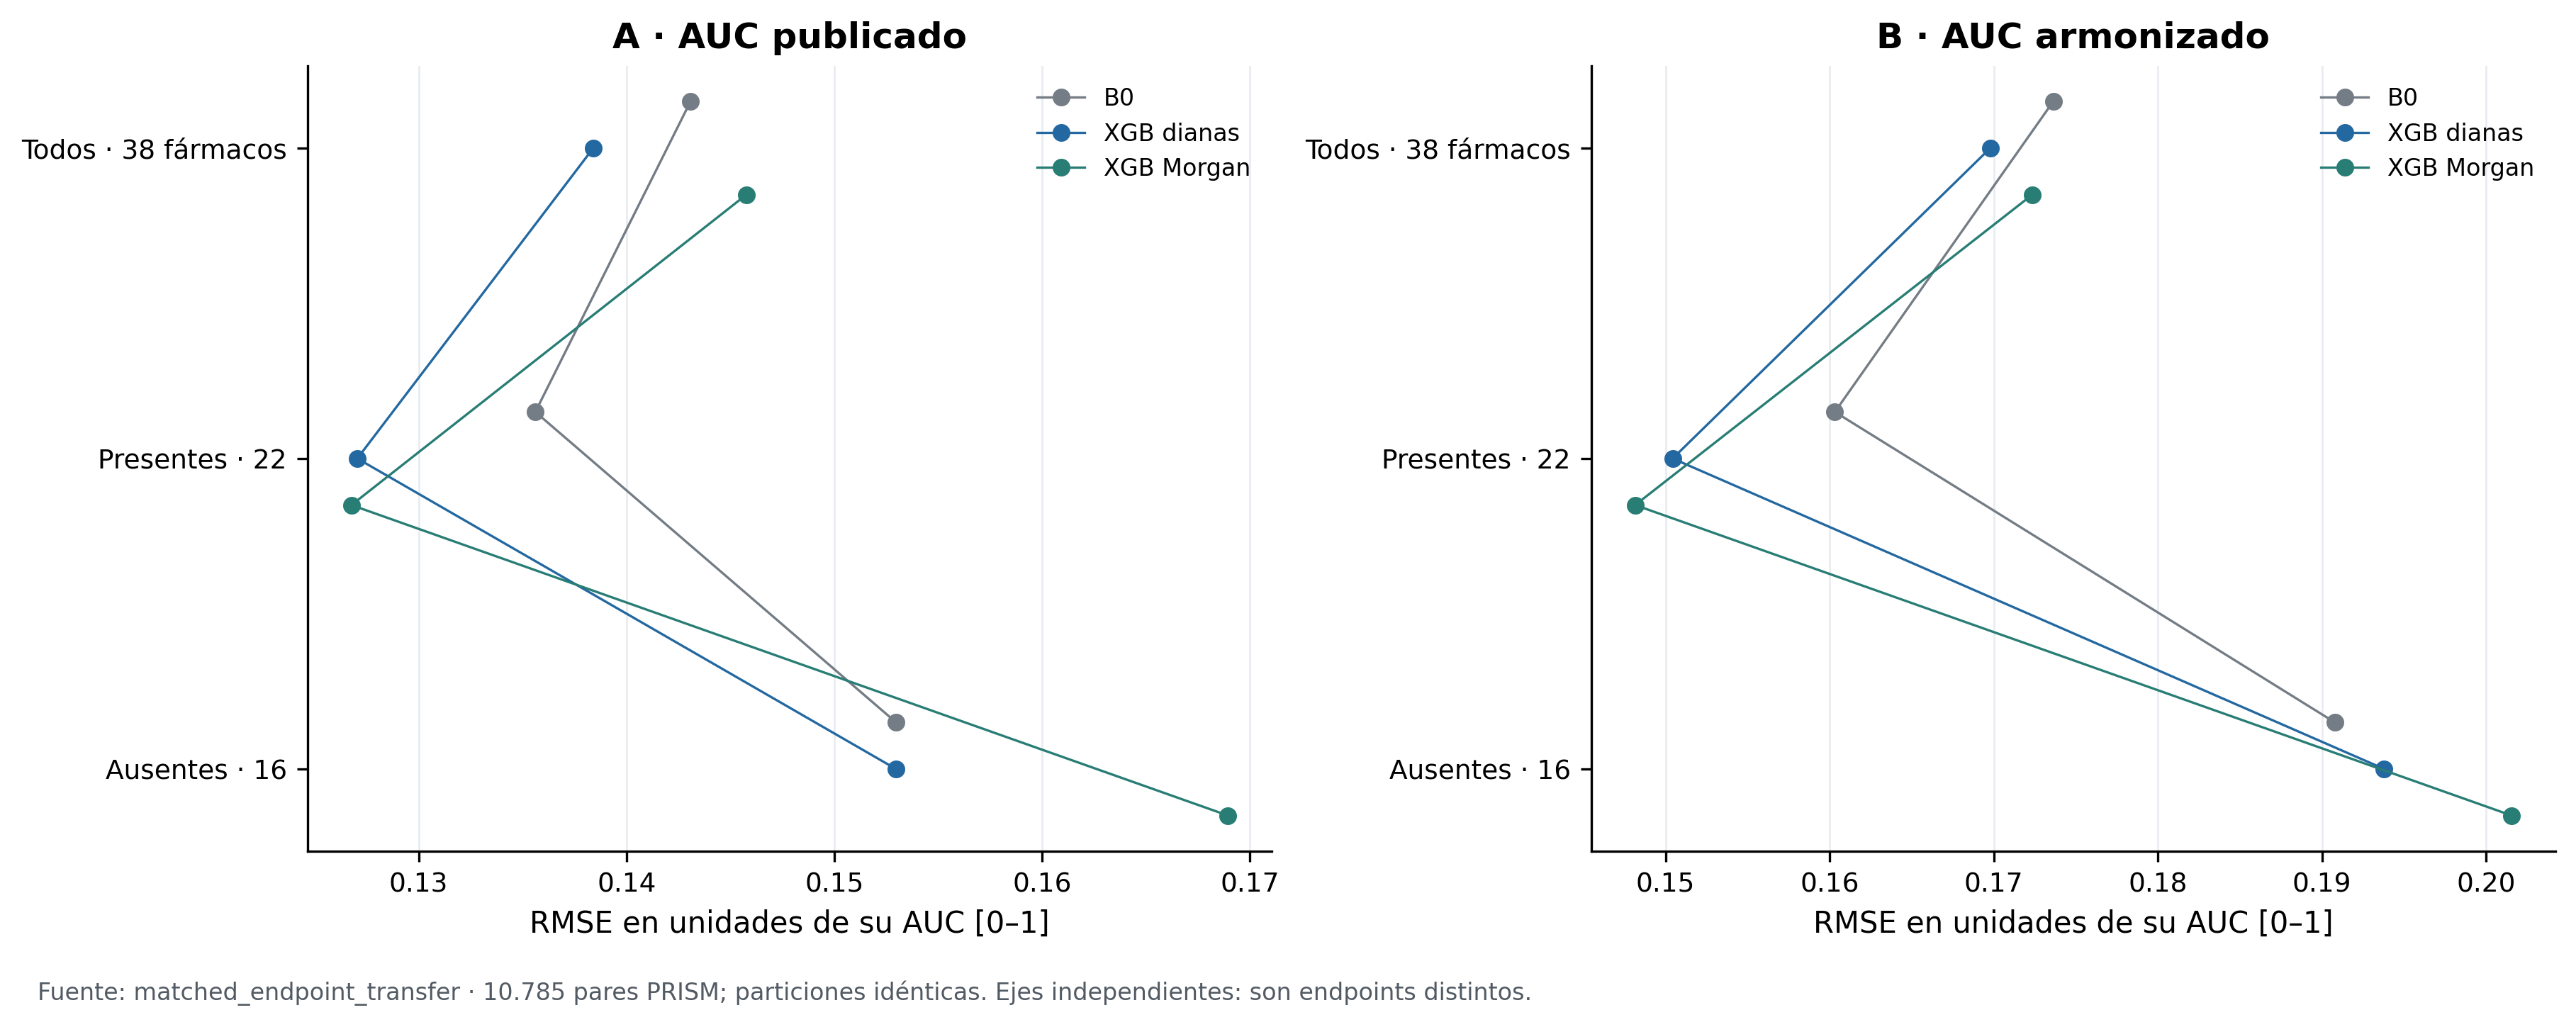

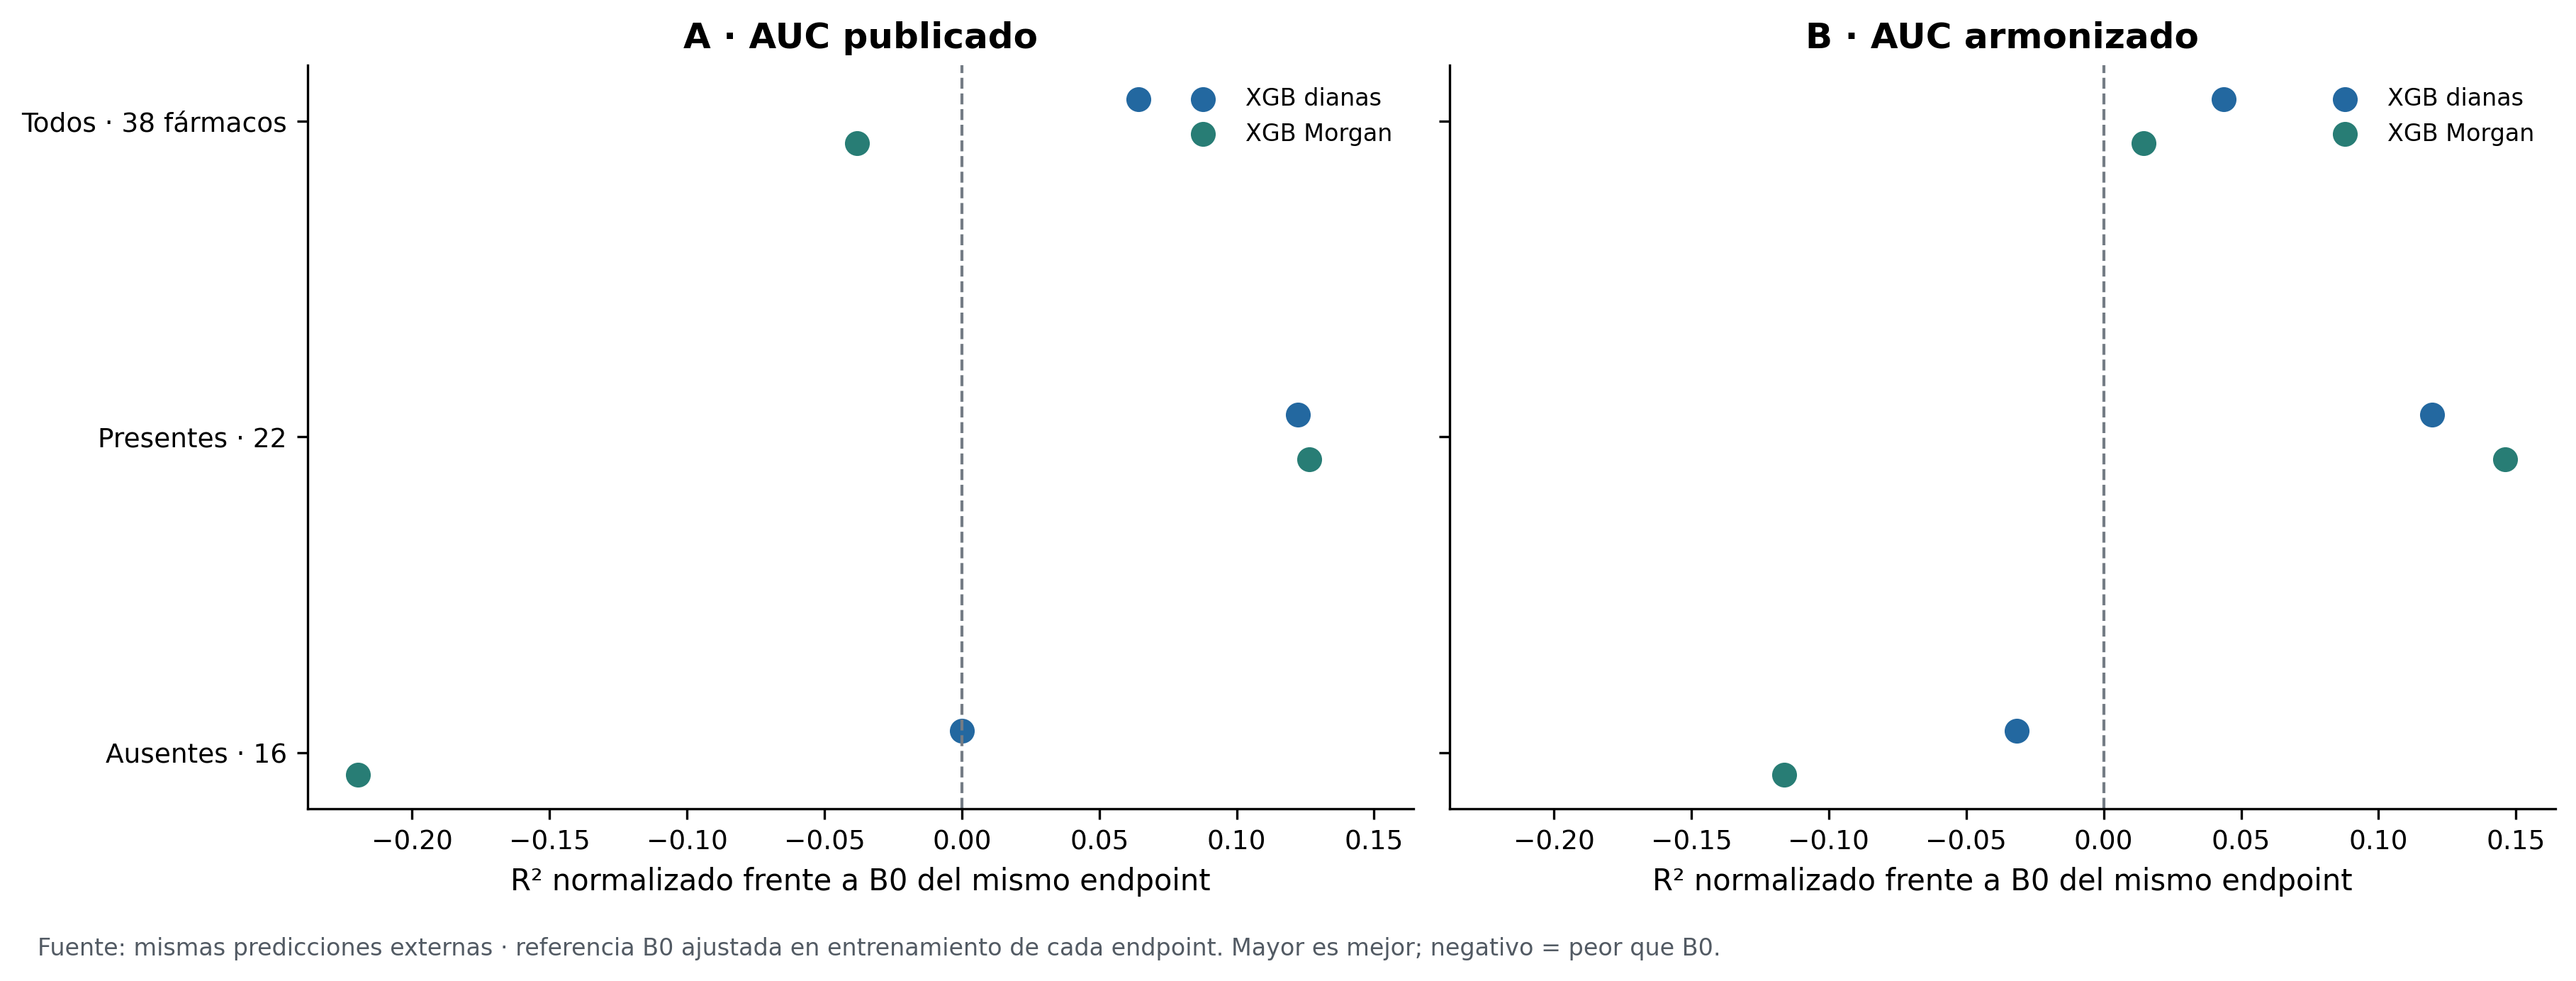

In [12]:
transfer = pd.DataFrame(report["matched_endpoint_transfer"])
model_order = ["mean_effects", "targets_expression_pca", "morgan_expression_pca"]
model_names = ["B0", "XGB dianas", "XGB Morgan"]
strata = ["all", "seen_drugs", "unseen_drugs"]
strata_names = ["Todos · 38 fármacos", "Presentes · 22", "Ausentes · 16"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
for ax, endpoint, title in zip(axes, ["published_matched", "harmonized"],
                              ["A · AUC publicado", "B · AUC armonizado"]):
    for model, label, offset, color in zip(model_order, model_names, [-.15,0,.15], [GRAY,BLUE,TEAL]):
        data = transfer.loc[(transfer.endpoint==endpoint) & (transfer.model==model)].set_index("stratum")
        ax.plot(data.loc[strata,"rmse"], np.arange(3)+offset, "o-", color=color, ms=5,
                lw=.8, label=label)
    ax.set(yticks=range(3), yticklabels=strata_names, xlabel="RMSE en unidades de su AUC [0–1]",
           title=title)
    ax.invert_yaxis()
    ax.legend(frameon=False, fontsize=8)
    ax.grid(axis="x", color="#E7EBEF", lw=.6)
finish(fig, "11_transferencia_por_endpoint", "Fuente: matched_endpoint_transfer · "
       "10.785 pares PRISM; particiones idénticas. Ejes independientes: son endpoints distintos.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True, sharey=True, layout="constrained")
for ax, endpoint, title in zip(axes, ["published_matched", "harmonized"],
                              ["A · AUC publicado", "B · AUC armonizado"]):
    for model, label, offset, color in zip(model_order[1:], model_names[1:], [-.07,.07], [BLUE,TEAL]):
        data = transfer.loc[(transfer.endpoint==endpoint) & (transfer.model==model)].set_index("stratum")
        ax.scatter(data.loc[strata,"r2_normalized"], np.arange(3)+offset, color=color, s=55, label=label)
    ax.axvline(0, color=GRAY, ls="--", lw=1)
    ax.set(yticks=range(3), yticklabels=strata_names, xlabel="R² normalizado frente a B0 del mismo endpoint",
           title=title)
    ax.legend(frameon=False, fontsize=8)
axes[0].invert_yaxis()
finish(fig, "12_transferencia_normalizada", "Fuente: mismas predicciones externas · "
       "referencia B0 ajustada en entrenamiento de cada endpoint. Mayor es mejor; negativo = peor que B0.")

### Sensibilidad a la identidad química completa

Se evalúan predicciones ya congeladas de tres semillas sobre el AUC publicado.
El filtro full-InChIKey elimina dos correspondencias basadas únicamente en
conectividad: quedan **44 fármacos / 13.597 pares**, frente a 46 / 14.200.
No hay reentrenamiento ni selección de modelos con ese subconjunto.
Esas tres semillas replican el ajuste sobre una sola cohorte externa.

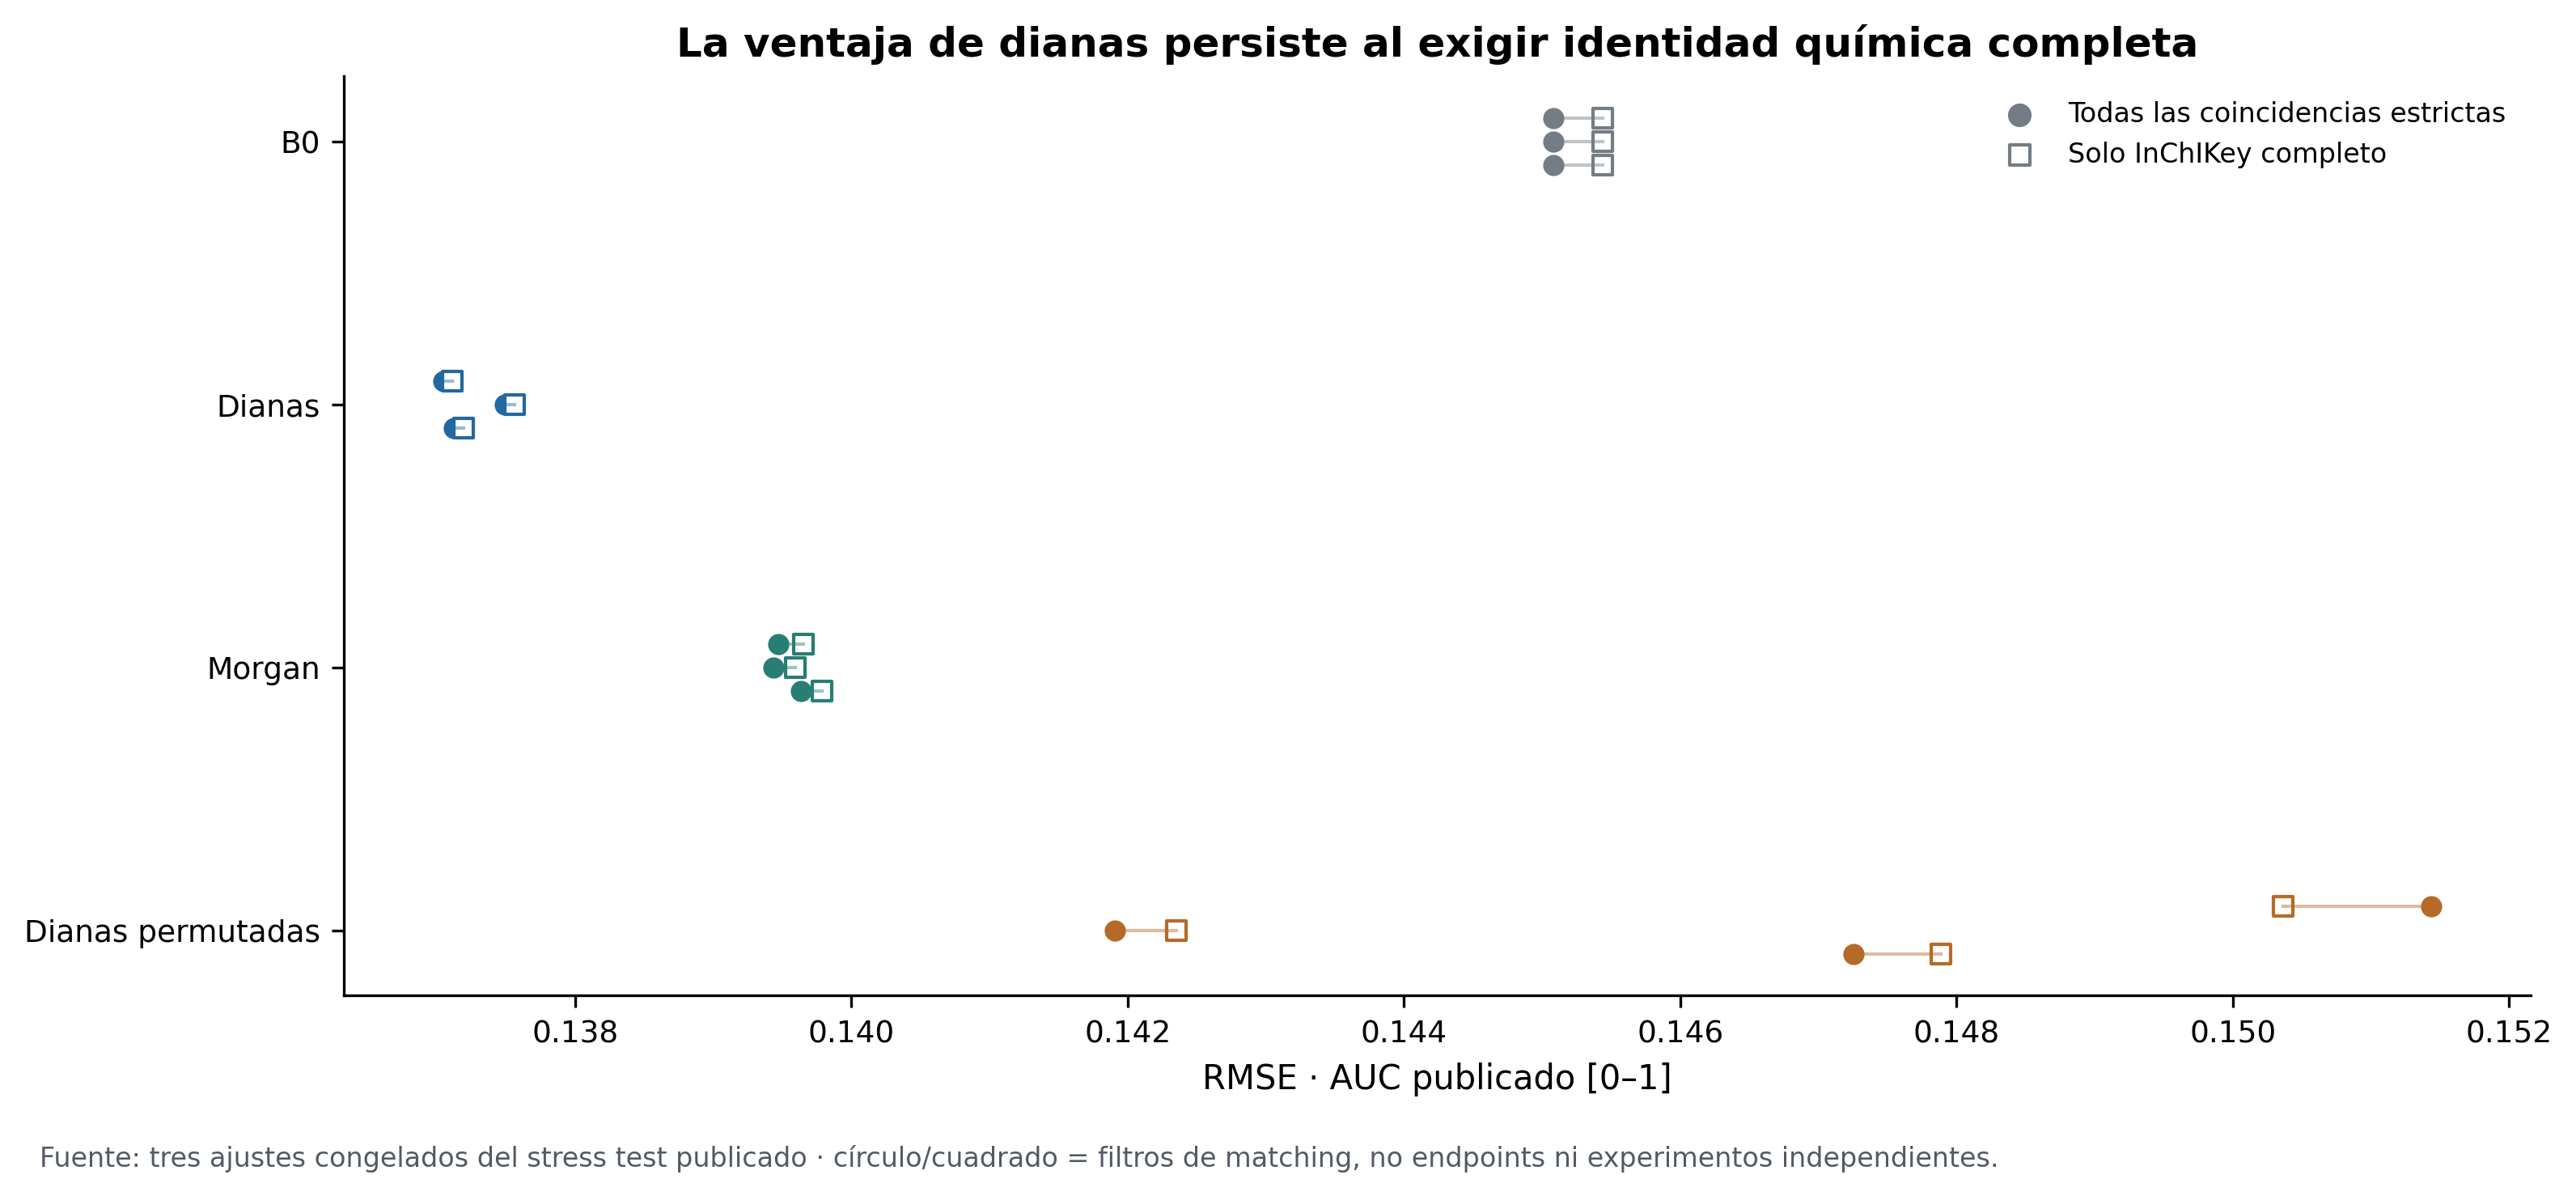

In [13]:
matching = pd.DataFrame(report["chemical_matching_sensitivity"]["per_seed"])
fig, ax = plt.subplots(figsize=(10.5,4.5), layout="constrained")
match_specs = [("B0", "B0", "mean_effects", "standard", GRAY),
               ("Dianas", "B6", "targets_expression_pca", "standard", BLUE),
               ("Morgan", "B6", "morgan_expression_pca", "standard", TEAL),
               ("Dianas permutadas", "B6", "targets_expression_pca", "shuffled", ORANGE)]
for y, (label, stage, model, variant, color) in enumerate(match_specs):
    data = matching.loc[(matching.stage==stage) & (matching.model==model) & (matching.variant==variant)]
    p = data.pivot(index="seed", columns="matching", values="rmse")
    assert len(p)==3, (label, data.variant.unique())
    for j, row in enumerate(p.itertuples()):
        yy = y + (j-1)*.09
        ax.plot([row.all_strict,row.full_inchikey_only], [yy,yy], color=color, alpha=.45, lw=1)
        ax.scatter(row.all_strict, yy, color=color, s=28, marker="o")
        ax.scatter(row.full_inchikey_only, yy, facecolor="white", edgecolor=color, s=32, marker="s")
ax.scatter([],[], color=GRAY, marker="o", label="Todas las coincidencias estrictas")
ax.scatter([],[], facecolor="white", edgecolor=GRAY, marker="s", label="Solo InChIKey completo")
ax.set(yticks=range(4), yticklabels=[x[0] for x in match_specs], xlabel="RMSE · AUC publicado [0–1]",
       title="La ventaja de dianas persiste al exigir identidad química completa")
ax.invert_yaxis()
ax.legend(frameon=False, fontsize=8, loc="upper right")
finish(fig, "13_sensibilidad_identidad_quimica", "Fuente: tres ajustes congelados del stress test publicado · "
       "círculo/cuadrado = filtros de matching, no endpoints ni experimentos independientes.")

## 6 · Incertidumbre: cobertura y utilidad de los intervalos

### Calibración independiente en cold-drug

Se reservó el 15 % de las entidades de entrenamiento por ID, sin consultar
respuestas. Esas entidades no participan en ajuste ni early stopping. El radio
usa el máximo residual por grupo y el cuantil con corrección finita.
**Cobertura de grupo** exige cubrir todas sus respuestas; cobertura por fila
solo exige cubrir cada observación por separado. Los intervalos amplios pueden
tener alta cobertura por fila y escasa utilidad. Los modelos con reserva de
calibración usan menos entrenamiento que la comparación principal.

`Raw` conserva la predicción original; `afín` usa una transformación no negativa
ajustada en validación. Ambas se reportan sin escoger por rendimiento en test.

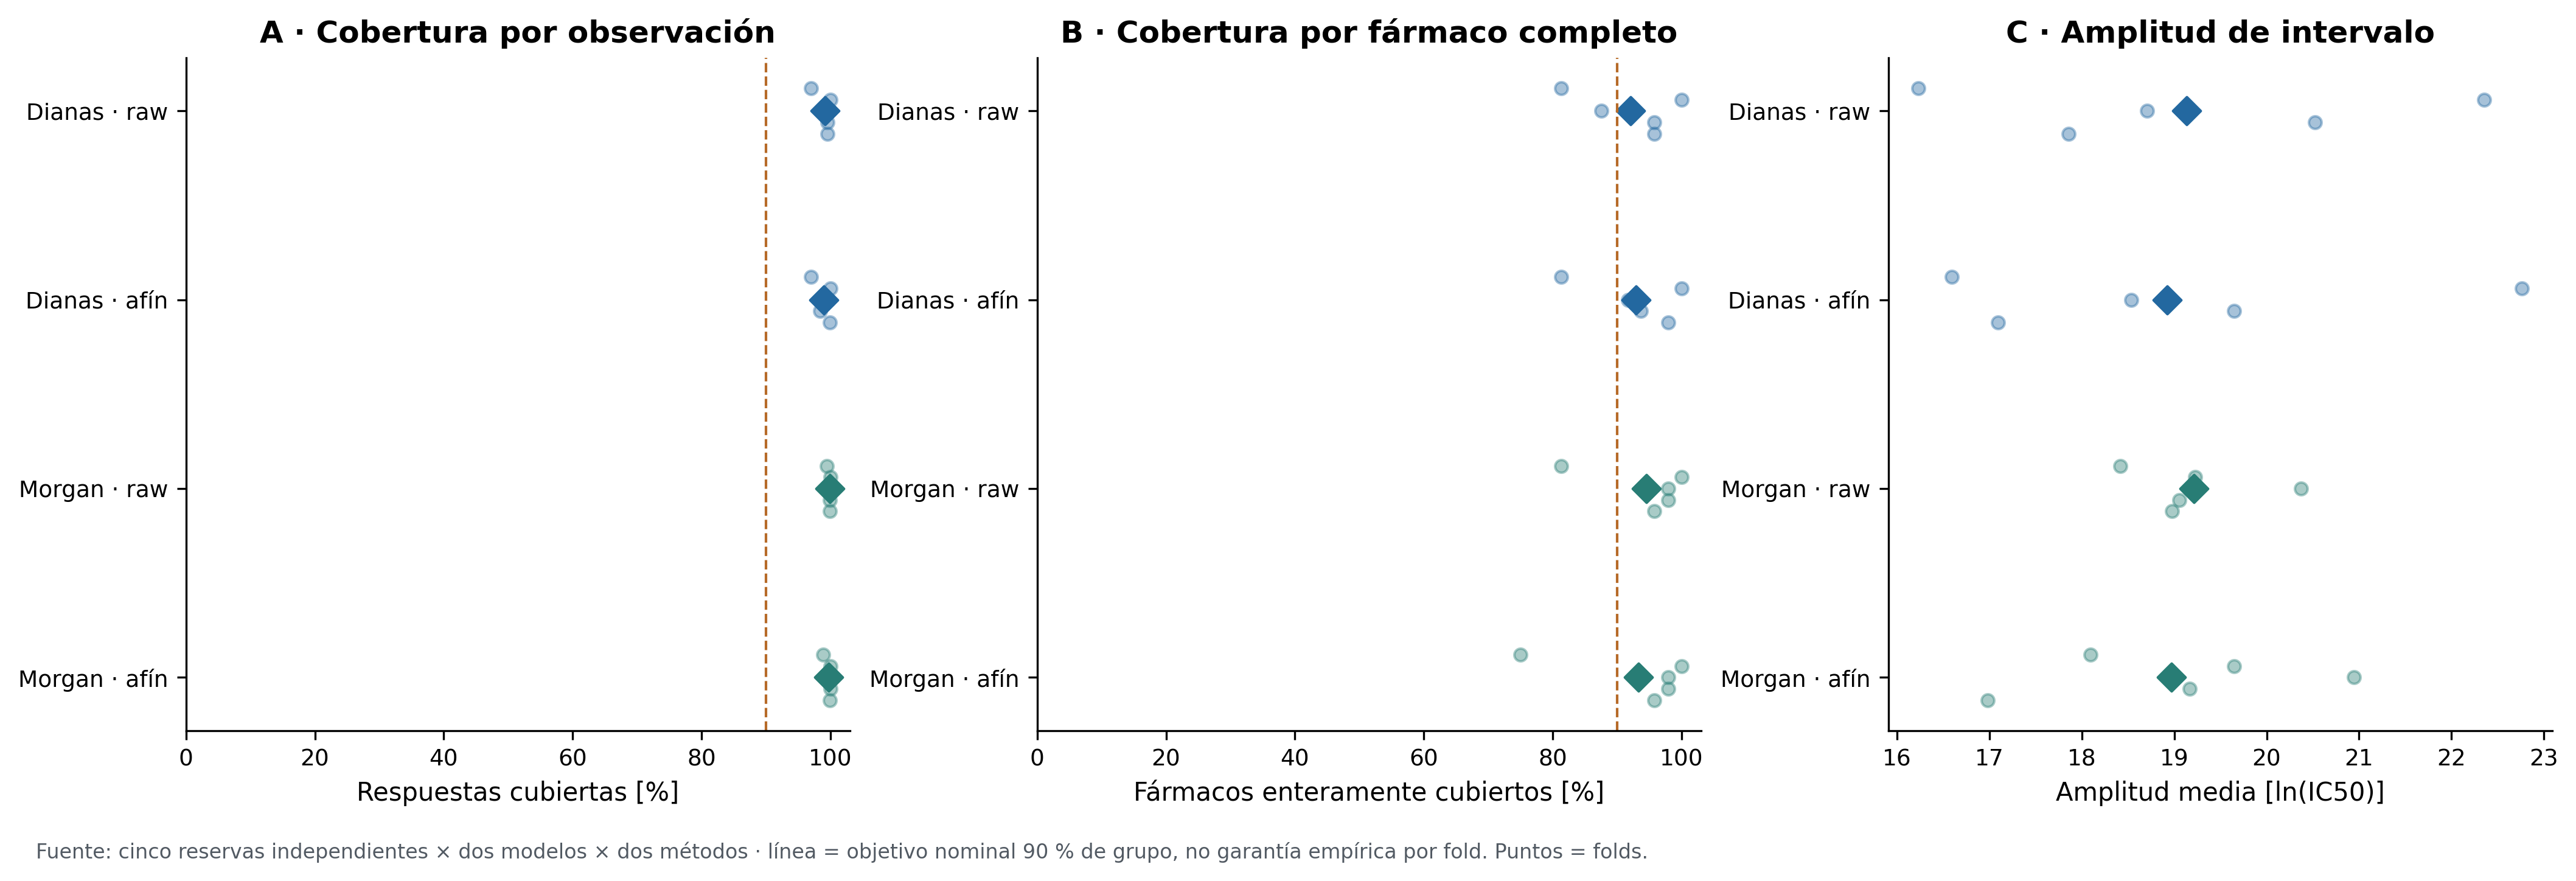

In [14]:
cal = pd.DataFrame(report["independent_calibration"])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), layout="constrained")
labels = ["Dianas · raw", "Dianas · afín", "Morgan · raw", "Morgan · afín"]
combinations = [("targets_expression_pca","raw",BLUE),
                ("targets_expression_pca","affine_validation",BLUE),
                ("morgan_expression_pca","raw",TEAL),
                ("morgan_expression_pca","affine_validation",TEAL)]
for y, (model, method, color) in enumerate(combinations):
    data = cal.loc[(cal.model==model) & (cal.method==method)].sort_values("fold")
    assert len(data)==5
    for ax, metric in zip(axes, ["row_coverage", "whole_group_coverage", "mean_width"]):
        values = data[metric].to_numpy() * (100 if metric != "mean_width" else 1)
        ax.scatter(values, y+np.linspace(-.12,.12,5), color=color, alpha=.4, s=25)
        ax.scatter(values.mean(), y, color=color, s=60, marker="D")
for ax, title, xlabel in zip(axes, ["A · Cobertura por observación", "B · Cobertura por fármaco completo",
                                   "C · Amplitud de intervalo"],
                            ["Respuestas cubiertas [%]", "Fármacos enteramente cubiertos [%]",
                             "Amplitud media [ln(IC50)]"]):
    ax.set(yticks=range(4), yticklabels=labels, xlabel=xlabel, title=title)
    ax.invert_yaxis()
for ax in axes[:2]:
    ax.axvline(90, color=ORANGE, ls="--", lw=1)
    ax.set_xlim(0,103)
finish(fig, "14_calibracion_cold_drug", "Fuente: cinco reservas independientes × dos modelos × dos métodos · "
       "línea = objetivo nominal 90 % de grupo, no garantía empírica por fold. Puntos = folds.")

### La cobertura simultánea no se conserva al cambiar de ensayo

La calibración usa **93 células reservadas de GDSC**; el test contiene
**335 células PRISM**. Los intervalos AUC se recortan explícitamente a [0,1].
La cobertura por observación ronda el 93–95 %, pero la cobertura por célula
completa es solo **17,9 % con Morgan y 24,8 % con dianas (raw)**.
La línea del 90 % es el objetivo nominal, **no una garantía válida bajo este
cambio de distribución**. El resultado es una limitación central del proyecto.

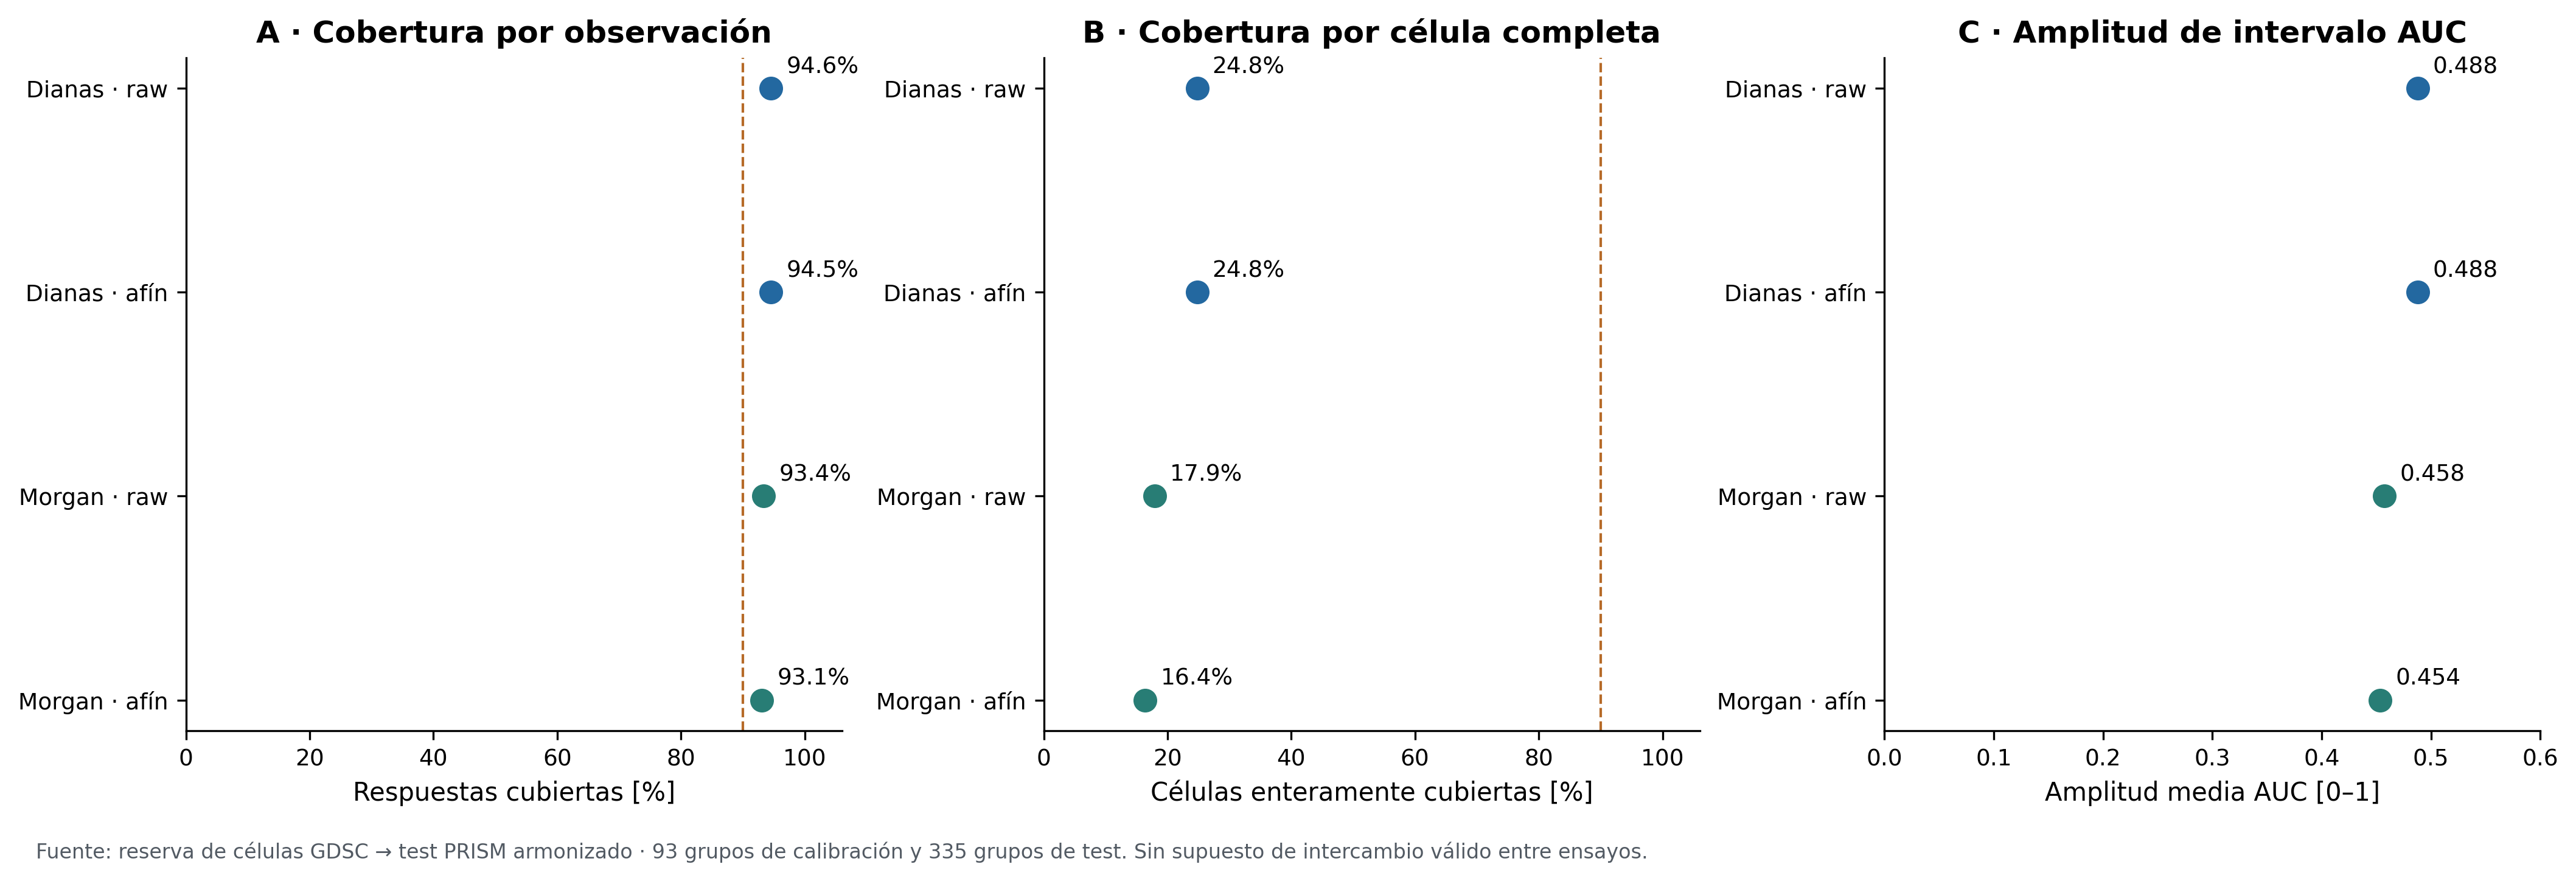

In [15]:
tcal = pd.DataFrame(report["transfer_independent_calibration"])
fig, axes = plt.subplots(1, 3, figsize=(14,4.4), layout="constrained")
for y, (model, method, color) in enumerate(combinations):
    row = tcal.loc[(tcal.model==model) & (tcal.method==method)].iloc[0]
    for ax, metric in zip(axes, ["row_coverage", "whole_group_coverage", "mean_width"]):
        value = row[metric] * (100 if metric!="mean_width" else 1)
        ax.scatter(value, y, color=color, s=70)
        ax.annotate(f"{value:.1f}%" if metric!="mean_width" else f"{value:.3f}",
                    (value,y), xytext=(6,6), textcoords="offset points", fontsize=9)
for ax, title, xlabel in zip(axes, ["A · Cobertura por observación", "B · Cobertura por célula completa",
                                   "C · Amplitud de intervalo AUC"],
                            ["Respuestas cubiertas [%]", "Células enteramente cubiertas [%]",
                             "Amplitud media AUC [0–1]"]):
    ax.set(yticks=range(4), yticklabels=labels, xlabel=xlabel, title=title)
    ax.invert_yaxis()
for ax in axes[:2]:
    ax.axvline(90, color=ORANGE, ls="--", lw=1)
    ax.set_xlim(0,106)
axes[2].set_xlim(0,.6)
finish(fig, "15_calibracion_transferencia", "Fuente: reserva de células GDSC → test PRISM armonizado · "
       "93 grupos de calibración y 335 grupos de test. Sin supuesto de intercambio válido entre ensayos.")

## 7 · Inventario completo y trazabilidad

La siguiente figura incluye **las 23 variantes finales y las cinco referencias
B0**. Incluye controles y ajustes con reserva de calibración, aunque estos
últimos usan menos datos de entrenamiento. Cada valor es una media no ponderada
de cinco folds. Las correlaciones indefinidas se omiten, no se imputan a cero.
El resumen detallado y las 105 comparaciones bootstrap se exportan a CSV.

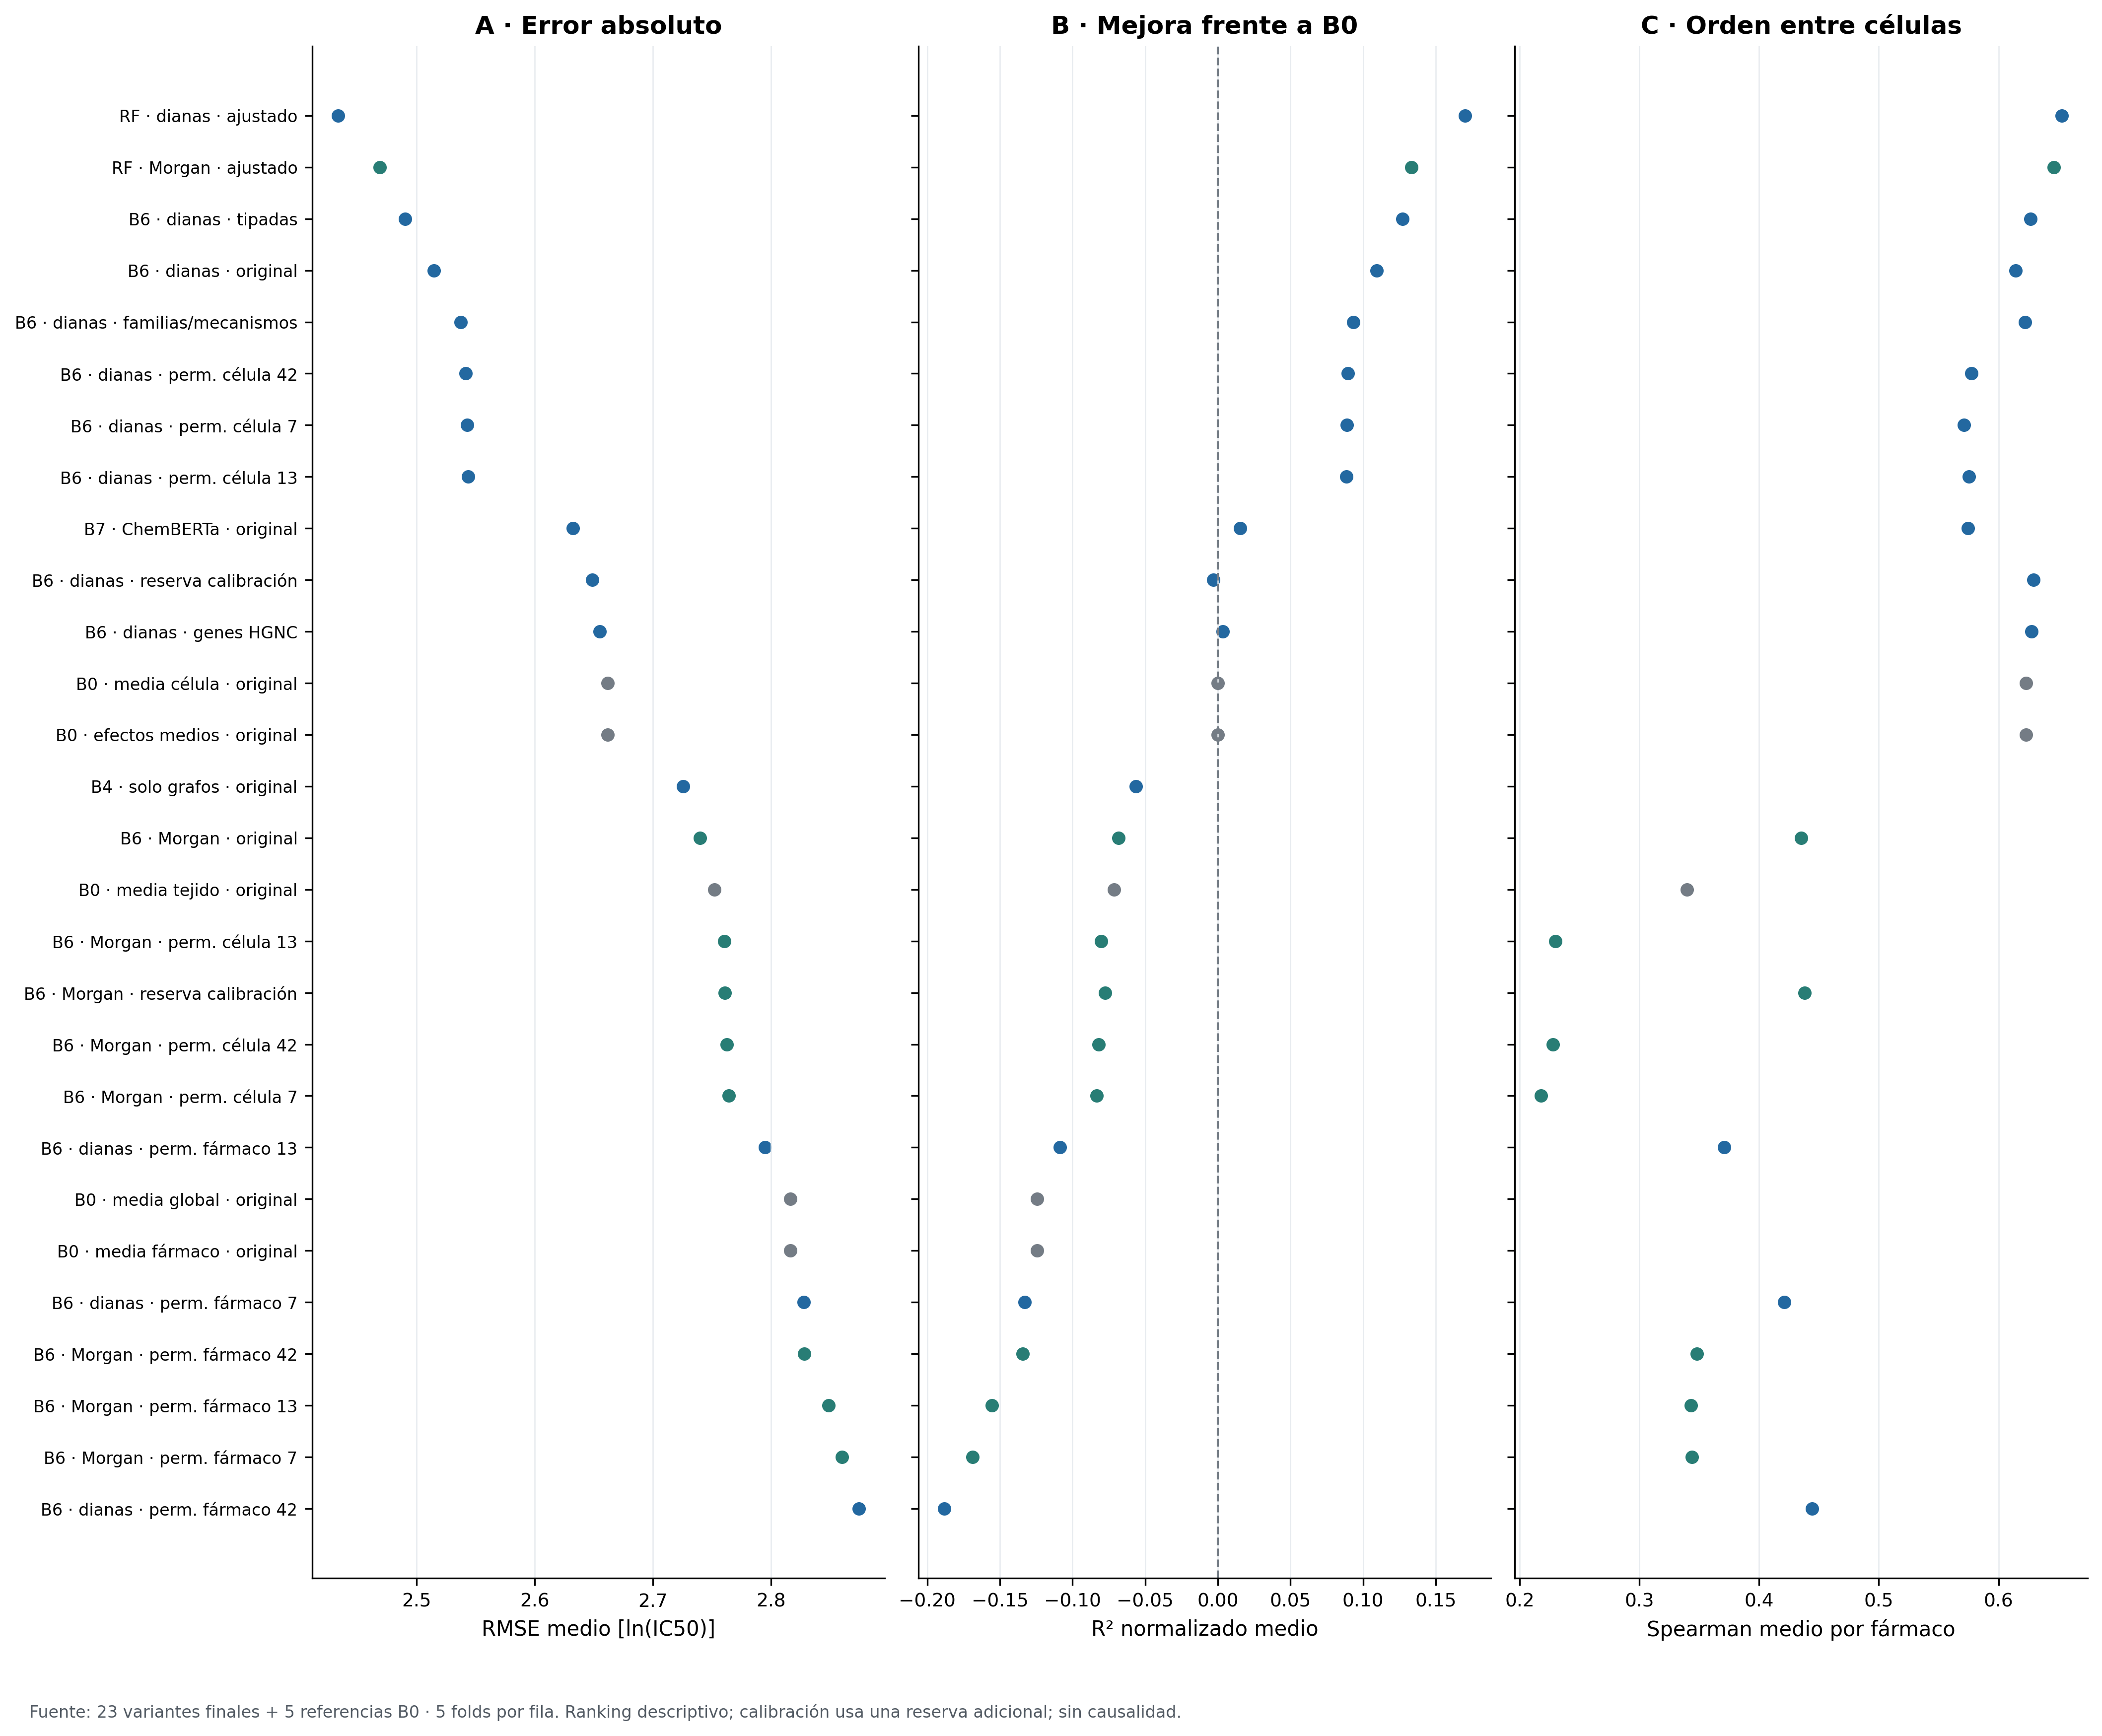

,comparison,n_folds,rmse_mean,rmse_sd,r2_normalized_mean,spearman_per_drug_mean
0,RF · dianas · ajustado,5,2.434,0.484,0.170,0.653
1,RF · Morgan · ajustado,5,2.469,0.345,0.133,0.646
2,B6 · dianas · tipadas,5,2.491,0.428,0.127,0.627
3,B6 · dianas · original,5,2.515,0.424,0.109,0.614
4,B6 · dianas · familias/mecanismos,5,2.537,0.440,0.093,0.622
5,B6 · dianas · perm. célula 42,5,2.542,0.421,0.089,0.577
6,B6 · dianas · perm. célula 7,5,2.543,0.424,0.089,0.571
7,B6 · dianas · perm. célula 13,5,2.544,0.426,0.088,0.575
8,B7 · ChemBERTa · original,5,2.632,0.366,0.015,0.574
9,B6 · dianas · reserva calibración,5,2.649,0.347,-0.003,0.629


In [16]:
agg = test.groupby(["stage","model","variant"], as_index=False).agg(
    n_folds=("fold","nunique"), rmse_mean=("rmse","mean"), rmse_sd=("rmse","std"),
    r2_normalized_mean=("r2_normalized","mean"),
    spearman_per_drug_mean=("spearman_per_drug","mean"))
assert len(agg)==28 and agg.n_folds.eq(5).all()
short_model = {"targets_expression_pca":"dianas", "morgan_expression_pca":"Morgan",
               "pretrained_drug_expression_pca":"ChemBERTa", "graph_only":"solo grafos",
               "mean_effects":"efectos medios", "cell_mean":"media célula",
               "drug_mean":"media fármaco", "global_mean":"media global", "tissue_mean":"media tejido"}
short_variant = {"standard":"original", "tuned":"ajustado", "targets_genes":"genes HGNC",
                 "targets_mechanisms":"familias/mecanismos", "targets_typed":"tipadas",
                 "independent_calibration":"reserva calibración"}
def label_row(row):
    variant = short_variant.get(row.variant, row.variant.replace("cell_permuted_","perm. célula ")
                               .replace("drug_permuted_","perm. fármaco "))
    return f"{row.stage} · {short_model.get(row.model,row.model)} · {variant}"
agg["comparison"] = [label_row(row) for row in agg.itertuples()]
agg = agg.sort_values("rmse_mean").reset_index(drop=True)
fig, axes = plt.subplots(1,3, figsize=(14,11), sharey=True, layout="constrained")
for ax, column, title, xlabel in zip(axes,
    ["rmse_mean","r2_normalized_mean","spearman_per_drug_mean"],
    ["A · Error absoluto", "B · Mejora frente a B0", "C · Orden entre células"],
    ["RMSE medio [ln(IC50)]", "R² normalizado medio", "Spearman medio por fármaco"]):
    for y, row in enumerate(agg.itertuples()):
        value = getattr(row,column)
        if pd.notna(value):
            color = GRAY if row.stage=="B0" else (TEAL if "morgan" in row.model else BLUE)
            ax.scatter(value,y,color=color,s=30)
    ax.set(yticks=range(len(agg)), xlabel=xlabel, title=title)
    ax.grid(axis="x", color="#E7EBEF", lw=.6)
axes[0].set_yticklabels(agg.comparison,fontsize=8)
axes[0].invert_yaxis()
axes[1].axvline(0,color=GRAY,ls="--",lw=1)
finish(fig, "16_inventario_completo", "Fuente: 23 variantes finales + 5 referencias B0 · "
       "5 folds por fila. Ranking descriptivo; calibración usa una reserva adicional; sin causalidad.")
agg.to_csv(OUT/"metricas_completas.csv",index=False)
boot.to_csv(OUT/"bootstrap_completo.csv",index=False)
tcal.to_csv(OUT/"calibracion_transferencia.csv",index=False)
cal.to_csv(OUT/"calibracion_cold_drug.csv",index=False)
display(style_table(agg[["comparison","n_folds","rmse_mean","rmse_sd",
                        "r2_normalized_mean","spearman_per_drug_mean"]],
                    {c:"{:.3f}" for c in ["rmse_mean","rmse_sd","r2_normalized_mean",
                                          "spearman_per_drug_mean"]}))

### Verificación del software y de las representaciones

**182 tests**, Ruff y mypy (66 archivos de código) pasaron en el checkpoint.
Estas comprobaciones verifican contratos del software; no demuestran que las
hipótesis científicas sean verdaderas. El API oficial DrEvalPy 1.5.1 aporta
450 comprobaciones: 410 acuerdos numéricos y 40 diferencias documentadas por
la convención de correlación constante. No se reentrenó el benchmark DrEval.

ChemBERTa queda fijado en el commit
`ed8a5374f2024ec8da53760af91a33fb8f6a15ff` (238 fármacos × 384 dimensiones).
PCA se ajusta dentro del entrenamiento. La representación congelada no elimina
por sí misma el sesgo de dominio ni garantiza ventaja frente a un baseline.

In [17]:
checks = [c for f in dreval["folds"] for c in f["checks"]]
assert len(checks)==450
assert all(c["agreement"] or c["constant_correlation_convention"] for c in checks)
assert annotation["output_sha256"]==report["annotation_sha256"]
assert embedding["status"]=="verified"
provenance = pd.DataFrame([
    {"Artefacto":"Anotaciones HGNC", "Estado":"hash coincidente", "SHA-256 / revisión":annotation["output_sha256"]},
    {"Artefacto":"Snapshot HGNC", "Estado":"congelado 2026-09-30", "SHA-256 / revisión":annotation["hgnc_sha256"]},
    {"Artefacto":"ChemBERTa", "Estado":"238 × 384; verificado", "SHA-256 / revisión":embedding["resolved_revision"]},
    {"Artefacto":"Embeddings", "Estado":"provenance audit passed", "SHA-256 / revisión":embedding["output_sha256"]},
    {"Artefacto":"DrEvalPy 1.5.1", "Estado":"0 diferencias sin explicar", "SHA-256 / revisión":dreval["official_wheel_sha256"]},
])
display(style_table(provenance))
source_inventory = pd.DataFrame([{"archivo":k,"sha256":v}
                                 for k,v in snapshot["source_sha256"].items()])
source_inventory.to_csv(OUT/"procedencia_artefactos.csv",index=False)
manifest = {"figures":generated,"formats":["png (300 dpi)","svg","pdf"],
            "source_report":"data/reports/roadmap_2_6_summary.json",
            "source_plot_snapshot":"data/reports/final_results_plot_data.json",
            "python":platform.python_version(),"numpy":np.__version__,
            "pandas":pd.__version__,"matplotlib":matplotlib.__version__,
            "figure_count":len(generated),"conclusions":"Exploratory; no clinical or causal claims"}
(OUT/"manifest.json").write_text(json.dumps(manifest,indent=2)+"\n",encoding="utf-8")
print(f"{len(generated)} figuras exportadas a PNG, SVG y PDF en {OUT}")
print("CSV: métricas, bootstrap, calibración y procedencia de artefactos.")

,Artefacto,Estado,SHA-256 / revisión
0,Anotaciones HGNC,hash coincidente,43e2c1198e9b00b6f80c8b59041ebb52a72ef9133d1f0997cace9e0f441a86a9
1,Snapshot HGNC,congelado 2026-09-30,91d0ad20c34f26fb12c8cce3f80a65a6fc694f3a508040b19f6bfa29ae0d889e
2,ChemBERTa,238 × 384; verificado,ed8a5374f2024ec8da53760af91a33fb8f6a15ff
3,Embeddings,provenance audit passed,3a9fb4540460136d321e147e17566a02806aaacafa2931f56d00ebab355731a9
4,DrEvalPy 1.5.1,0 diferencias sin explicar,8ebe968755ff390a6025e2b48bcac8395702b65e96ad0554d4d23aae50525b86


16 figuras exportadas a PNG, SVG y PDF en C:\Users\Paess\Documents\GitHub\multimodal-cancer-drug-response\figures\final_results
CSV: métricas, bootstrap, calibración y procedencia de artefactos.


## Interpretación final

- **Baseline competitivo:** RF con dianas + expresión, RMSE medio 2,434.
  La mejora de la media no implica significación universal en cada fold.
- **Semántica de anotación:** genes solos pierden información frente a una
  vista que conserva familias/mecanismos. Esto limita la interpretación causal.
- **Armonización parcial:** aumenta ligeramente la concordancia de rangos,
  sin reducir la discrepancia absoluta ni corregir duración/plataforma.
- **Transferencia limitada:** la dificultad aumenta para fármacos ausentes
  del entrenamiento; la ventaja con dianas persiste con matching químico completo.
- **Incertidumbre no resuelta:** la cobertura simultánea por célula está muy
  por debajo del objetivo nominal al transferir a PRISM.

### Reproducción y próximos pasos
Instale el extra de visualización: `pip install -e ".[notebooks]"`.
Abra `notebooks/final_results.ipynb` y ejecute todas las celdas con un kernel
Python. Los informes y el snapshot compacto están versionados; no hace falta
descargar datos crudos, disponer de GPU ni reentrenar para reproducir las figuras.
Para actualizar el snapshot tras **regenerar el informe canónico**, use
`python scripts/export_final_results_plot_data.py`; requiere los artefactos de
experimentos locales. No cambie solo una predicción y reutilice el informe antiguo.

La ejecución verificada deja el notebook con outputs y una versión HTML
autocontenida en `results/reports/final_results/final_results.html`.
Las figuras individuales están en `figures/final_results/`.

Consulte [roadmap](../docs/research_roadmap.md),
[protocolos de los pasos 2–6](../docs/roadmap_2_6.md),
[evaluación](../docs/evaluation_protocol.md) y
[literatura](../docs/related_work.md). Sigue pendiente refrescar otros splits y
arquitecturas, incorporar representaciones/ómicas adicionales y confirmar el
protocolo en una cohorte externa aún no examinada.